# The AgMIP calibration protocol with diffWOFOST

![diffWOFOST logo](https://raw.githubusercontent.com/WUR-AI/diffWOFOST/refs/heads/main/docs/logo/diffwofost.png)

The AgMIP calibration protocol provides a structured approach to crop-model calibration using multiple observation types. It specifies how to group observations, select parameters, estimate their values, and evaluate model fit.

This notebook applies the protocol to the public French winter-wheat dataset from AgMIP Calibration Phase IV, using **diffWOFOST**, a differentiable implementation of WOFOST. In a differentiable model the simulated observations are a smooth function of the parameters, so the sum of squares has a gradient and Adam can follow it. That gradient search is compared with the reference implementation's multi-start Nelder–Mead search.

The workflow follows the protocol's eight steps: documenting the model and data, calibrating phenology, calibrating biomass and nitrogen-related variables, selecting parameters, jointly refitting the selected parameters, and evaluating goodness of fit. The objective functions and selection procedure are intended to follow the protocol; model-specific adaptations are documented below.


## Dataset

AgMIP Calibration Phase IV uses the French winter-wheat cultivar Apache from Arvalis variety trials. The dataset covers 22 site-years: 14 calibration environments and eight held-out evaluation environments, separated by site and year. The public data are available in [https://github.com/sbuis/AgMIP-Calibration-Phase-IV](https://github.com/sbuis/AgMIP-Calibration-Phase-IV).

The input file covers all 22 environments, but the public observation file contains only the 14 calibration environments. The official evaluation observations are not available, so this notebook can assess calibration fit but cannot independently evaluate predictive performance on the official evaluation set. See Wallach et al. (2024, 2025) for the AgMIP protocol and evaluation context.

The observation file does not contain the `Date_BBCH10` variable listed in the units table. Emergence dates are therefore unavailable for calibration. A separate [synthetic dataset](https://github.com/sbuis/AgMIP_calibration_PhaseIV_step2_synthetic_experiment) represents the same environments simulated with STICS and known generating parameters; it is useful for testing parameter recovery, but it is distinct from the real-data experiment considered here.


## Applying the protocol to WOFOST

The AgMIP protocol is model-independent, but its application depends on the observations and simulated variables available in WOFOST. The main adaptations are:

- **Phenology:** heading (BBCH55) is used as a proxy for anthesis (DVS 1), and maturity (BBCH90) represents DVS 2. BBCH30 is not fitted because it has no distinct WOFOST development-stage threshold. Emergence dates (BBCH10) are unavailable, so `TSUMEM` remains fixed at its Arminda default.
- **Observation groups:** biomass is fitted on a logarithmic scale; yield uses `TWSO`; plant nitrogen is harvest nitrogen as a percentage of above-ground biomass; and grain protein is estimated as 5.7 times the nitrogen percentage of `TWSO`. Grain and ear number are not fitted because corresponding WOFOST states are unavailable.
- **Parameters and selection:** calibration starts from Arminda cultivar parameters. Major parameters are fitted first, then candidate parameters are tested sequentially and retained according to AICc.
- **Optimization:** Adam is compared with multi-start Nelder–Mead. The optimizer is not prescribed by the protocol, but the objective functions, selection procedure, and final weighted refit are preserved.
- **Evaluation:** the 14 public site-years are used for calibration. Without observations from the eight held-out environments, independent predictive evaluation is not possible here.

Soil hydraulic properties, rooting depth, initial mineral nitrogen, organic-matter properties, and fertilizer transformations are fixed inputs rather than calibrated parameters. The following sections document the principal assumptions and model-specific choices.


## Setup

The next cell installs `diffWOFOST` from the `agmip-calibration-protocol` branch and loads the French AgMIP files. The WOFOST 8.1 winter-wheat parameter file is downloaded on first use if it is not already available locally.

### Optimization settings

Adam uses 20 Latin-hypercube starts for groups with two major parameters and five for groups with one major parameter or for each candidate fit. For candidate fits, one start uses the best parameter vector from the preceding fit; the other starts explore the permitted bounds. The weighted refit uses 20 starts, following the default in `CroptimizR::run_protocol_agmip`.

The initial learning rate is 0.25 for phenology and 0.12 for the later groups. After three steps without a new best objective, the optimizer returns to the best vector, halves the learning rate, and resets Adam's momentum, up to four times. At the minimum learning rate, it stops after ten steps without improvement or at 80 steps, whichever comes first. These settings do not guarantee convergence; interpret results alongside the stopping diagnostics.

### Saved results and reproducibility

By default, `DO_NOT_RERUN = True` loads `agmip_calibration_results.json` and `agmip_nelder_mead_results.json` from the notebook directory. These files contain the search results from a full run of the notebook.

In [20]:
!pip install "diffwofost @ git+https://github.com/WUR-AI/diffWOFOST.git@agmip-calibration-protocol" matplotlib openpyxl

import datetime as dt
import json
import io
import tempfile
import urllib.request
import warnings
from pathlib import Path

import pandas as pd
import torch
from pcse.input import YAMLAgroManagementReader
from pcse.input import YAMLCropDataProvider
from pcse.models import Wofost81_NWLP_MLWB_SNOMIN

from diffwofost.physical_models.config import ComputeConfig
from diffwofost.physical_models.config import Configuration
from diffwofost.physical_models.crop.phenology import DVS_Phenology
from diffwofost.physical_models.engine import Engine
from diffwofost.physical_models.parameter_providers import ParameterProvider

warnings.filterwarnings("ignore", message="Converting a tensor with requires_grad")
ComputeConfig.set_device("cpu")
ComputeConfig.set_dtype(torch.float64)

# True loads the stored search and skips the Adam fits. False repeats them
# and overwrites agmip_calibration_results.json.
DO_NOT_RERUN = True
PATIENCE = 10
LR_PATIENCE = 3
LR_FACTOR = 0.5
LR_CUTS = 4
MIN_DELTA = 1.0e-4
PHENO_LR = 0.25


def rate_decision(score, best_ss, waited, cuts, rewound):
    """Step, halve the learning rate, or stop.

    Three steps without a new best return to the best parameters and halve
    the rate, up to four times. At the smallest rate the search stops after
    PATIENCE steps with no new best. The evaluation just after a rewind is
    the best point itself, so it does not count as a stall.
    """
    if rewound:
        return 0, cuts, False, "step"
    if score < best_ss - MIN_DELTA:
        return 0, cuts, False, "improve"
    waited += 1
    limit = PATIENCE if cuts >= LR_CUTS else LR_PATIENCE
    if waited < limit:
        return waited, cuts, False, "step"
    if cuts < LR_CUTS:
        return 0, cuts + 1, True, "decay"
    return waited, cuts, False, "stop"
RESULTS_NAME = "agmip_calibration_results.json"
RESULTS_URL = (
    "https://raw.githubusercontent.com/WUR-AI/diffWOFOST/"
    "agmip-calibration-protocol/docs/notebooks/agmip_calibration_results.json"
)
NELDER_NAME = "agmip_nelder_mead_results.json"
NELDER_URL = (
    "https://raw.githubusercontent.com/WUR-AI/diffWOFOST/"
    "agmip-calibration-protocol/docs/notebooks/agmip_nelder_mead_results.json"
)

PAIRS_NAME = "agmip_calibration_pairs.json"
PAIRS_URL = (
    "https://raw.githubusercontent.com/WUR-AI/diffWOFOST/"
    "agmip-calibration-protocol/docs/notebooks/agmip_calibration_pairs.json"
)
TRAJECTORY_NAME = "agmip_trajectories.json"
TRAJECTORY_URL = (
    "https://raw.githubusercontent.com/WUR-AI/diffWOFOST/"
    "agmip-calibration-protocol/docs/notebooks/agmip_trajectories.json"
)

STEP7_NAME = "agmip_step7_scores.json"
STEP7_URL = (
    "https://raw.githubusercontent.com/WUR-AI/diffWOFOST/"
    "agmip-calibration-protocol/docs/notebooks/agmip_step7_scores.json"
)


def results_file():
    """Results beside this notebook, or in the working directory on Colab."""
    here = Path.cwd().resolve()
    for base in (here, *here.parents):
        notebook_dir = base / "docs" / "notebooks"
        if notebook_dir.is_dir():
            return notebook_dir / RESULTS_NAME
    return here / RESULTS_NAME


def _jsonable(value):
    if isinstance(value, dict):
        return {str(key): _jsonable(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [_jsonable(item) for item in value]
    if isinstance(value, (str, bool)) or value is None:
        return value
    if isinstance(value, int):
        return int(value)
    return float(value)


def load_stored(name, url):
    """JSON beside this notebook, downloaded once if it is missing."""
    path = results_file().with_name(name)
    if not path.exists():
        print(f"No results file at {path}. Downloading the stored search.")
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(url, path)
    print(f"Loaded {path.name}.")
    return json.loads(path.read_text())


def load_results():
    """Stored parameters, sums of squares and AICc rows."""
    return load_stored(RESULTS_NAME, RESULTS_URL)


def load_nelder():
    """Stored Nelder-Mead comparison. Independent of DO_NOT_RERUN."""
    return load_stored(NELDER_NAME, NELDER_URL)


def save_results(payload):
    path = results_file()
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(_jsonable(payload), indent=2) + "\n")
    print(f"Stored calibration results in {path}.")


DATA_URL = "https://raw.githubusercontent.com/sbuis/AgMIP-Calibration-Phase-IV/main/data"


def crop_directory():
    """Winter-wheat parameter file shipped with the SNOMIN notebook."""
    here = Path.cwd().resolve()
    relative = (
        Path("docs/notebooks/snomin_calibration_data/crop"),
        Path("snomin_calibration_data/crop"),
        Path("crop"),
    )
    for base in (here, *here.parents):
        for name in relative:
            candidate = base / name
            if (candidate / "winterwheat.yaml").exists():
                return candidate
    destination = here / "snomin_calibration_data" / "crop"
    destination.mkdir(parents=True, exist_ok=True)
    names = ("winterwheat.yaml", "crops.yaml")
    for ref in ("agmip-calibration-protocol", "main"):
        base = (
            "https://raw.githubusercontent.com/WUR-AI/diffWOFOST/"
            f"{ref}/docs/notebooks/snomin_calibration_data/crop"
        )
        try:
            for name in names:
                urllib.request.urlretrieve(f"{base}/{name}", destination / name)
        except Exception:
            continue
        if (destination / "winterwheat.yaml").exists():
            return destination
    raise FileNotFoundError("winterwheat.yaml is not next to this notebook")


def download(name):
    with urllib.request.urlopen(f"{DATA_URL}/{name}") as response:
        return response.read()


observations = pd.read_csv(io.BytesIO(download("cal_4_obs_French_A.txt")), sep=r"\s+")
management = pd.read_csv(
    io.BytesIO(download("cal_4_input_data_French_A.txt")), sep=r"\s+", encoding="utf-8-sig"
)
units = pd.read_csv(io.BytesIO(download("cal_4_obs_French_units.csv")), sep=";", encoding="cp1252")
weather_book = pd.ExcelFile(io.BytesIO(download("cal_4_weather.xlsx")))
print(f"Calibration rows: {len(observations)}. Site-years in the input file: {len(management)}.")
print(f"Weather stations: {', '.join(weather_book.sheet_names)}.")
units


  Cloning https://github.com/WUR-AI/diffWOFOST.git (to revision agmip-calibration-protocol) to /tmp/pip-install-ek56pafi/diffwofost_6e399a6bf88e4c4ab8702f131f9c3e3b
  Running command git clone --filter=blob:none --quiet https://github.com/WUR-AI/diffWOFOST.git /tmp/pip-install-ek56pafi/diffwofost_6e399a6bf88e4c4ab8702f131f9c3e3b
  Running command git checkout -b agmip-calibration-protocol --track origin/agmip-calibration-protocol
  Switched to a new branch 'agmip-calibration-protocol'
  branch 'agmip-calibration-protocol' set up to track 'origin/agmip-calibration-protocol'.
  Resolved https://github.com/WUR-AI/diffWOFOST.git to commit 01cfcdc7627d3611a8d7c53ce3f3c6ef8006162b
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Calibration rows: 49. Site-years in the input file: 22.
Weather stations: station_1, station_2, station_3, station_4, station_5, station_6, station_7.


,Column name,Definition,Unit,Group
0,Date_BBCH10,Date of emergence,dd/mm/yyyy,NaN
1,Date_BBCH30,Date observed stem 1 cm. This is stage BBCH30 ...,dd/mm/yyyy,phenology
2,Date_BBCH55,This is stage BBCH55 (50% heading),dd/mm/yyyy,phenology
3,Date_BBCH90,Date of stage BBCH90 (maturity),dd/mm/yyyy,NaN
4,HarvestDate,Date of harvest,dd/mm/yyyy,NaN
5,Biomass,Aboveground biomass,g m-2,plant_biomass
6,EarsPerSqM,Ears per m2,m-2,ears
7,Grain_Number,grains per square meter,m-2,grain_number
8,ProteinContentGrain,Protein content at harvest. 0 means missing da...,%,seed_protein
9,N_in_biomassHarvest,Airborne nitrogen content at Machine harvest,%,plant_N_content


## Steps 1–5: applying the AgMIP protocol to WOFOST

**Step 1 — Default parameters.** The starting point is the Arminda cultivar parameterization from the WOFOST 8.1 winter-wheat parameter file. Apache, the target cultivar, is a French soft winter wheat. Arminda is used as the reference cultivar; parameters not selected for estimation remain at their Arminda defaults. Arminda uses vernalization (`IDSL = 2`). The WOFOST 8.1 nitrogen parameters were estimated for Arminda (Berghuijs et al., 2024).

**Steps 2–3 — Observations and variable groups.** Observations are grouped according to the WOFOST outputs they constrain. Variables without suitable simulated counterparts, or without the required measurements, are excluded.

**Step 4 — Major parameters.** Each group is first calibrated using a small set of parameters with clear mechanistic links to the observations. Heading (BBCH55) is used as a proxy for anthesis because the observations do not record anthesis directly.

**Step 5 — Candidate parameters.** Additional parameters are tested sequentially and retained only if they improve AICc. For phenology, vernalization parameters are tested before daylength because the crops are autumn-sown and experience different winter temperatures; the trial sites' relatively narrow latitude range (approximately 47–50°N) limits, but does not eliminate, photoperiod variation.

| Variable group | Observations used | Major parameters | Rationale |
|---|---|---|---|
| Phenology | Heading (BBCH55) and maturity (BBCH90) dates | `TSUM1`, `TSUM2` | Development to heading/anthesis proxy and maturity. |
| Biomass | Log-transformed above-ground biomass, `ln(TAGP)` | `AMAX_REF`, `SPAN` | Reference assimilation capacity and leaf lifespan affect biomass accumulation. |
| Plant nitrogen | Harvest nitrogen as a percentage of above-ground biomass | `RNUPTAKEMAX` | Maximum nitrogen uptake rate. |
| Yield | Grain yield represented by `TWSO` | `REALLOC_STEM_FRACTION` | Controls the fraction of stem biomass available for reallocation to grain. |
| Grain protein | Protein estimated as 5.7 times the nitrogen percentage of `TWSO` | `NMAXSO` | Maximum nitrogen concentration in storage organs. |

For grain protein, `NRESIDLV`, `NRESIDST`, and `TCNT` are additional candidates. They affect nitrogen retention in vegetative tissues and transfer to grain. Their selection status must be interpreted in light of the incomplete saved Adam candidate search. The observation file lacks emergence dates, and grain and ear number are not fitted because corresponding WOFOST states are unavailable.


In [21]:
variables = pd.DataFrame(
    [
        ["Date_BBCH30", "none", "phenology", "", "Stem elongation is not a WOFOST stage."],
        ["Date_BBCH55", "day when DVS reaches 1", "phenology", 1, "Heading, used as anthesis."],
        ["Date_BBCH90", "day when DVS reaches 2", "phenology", 1, "Maturity."],
        ["Biomass", "TAGP", "plant_biomass", 2, "g m-2 in the file, kg ha-1 in WOFOST."],
        ["N_in_biomassHarvest", "crop N / TAGP", "plant_N_content", 3, "Percent. Needs SNOMIN."],
        ["Grain_Yield", "TWSO", "yield", 4, "g m-2 in the file, kg ha-1 in WOFOST."],
        ["ProteinContentGrain", "storage-organ N / TWSO", "seed_protein", 5, "Percent."],
        ["EarsPerSqM", "none", "", "", "WOFOST does not simulate ear number."],
        ["Grain_Number", "none", "", "", "WOFOST does not simulate grain number."],
        ["LAI", "none", "", "", "Not in the observation file."],
    ],
    columns=["Observed", "Simulated", "Group", "Order", "Note"],
)
parameters = pd.DataFrame(
    [
        ["phenology", "major", "TSUM1", "Temperature sum, emergence to anthesis. Moves BBCH55."],
        ["phenology", "major", "TSUM2", "Temperature sum, anthesis to maturity. Moves BBCH90."],
        ["phenology", "candidate", "VERNSAT", "Saturated vernalization requirement."],
        ["phenology", "candidate", "VERNBASE", "Base vernalization requirement."],
        ["phenology", "candidate", "DLO", "Optimum daylength."],
        ["plant_biomass", "major", "AMAX_REF", "Assimilation level. One of the two allowed majors."],
        ["plant_biomass", "major", "SPAN", "Leaf lifespan. Sets how long biomass keeps accumulating."],
        ["plant_biomass", "candidate", "TDWI", "Initial biomass. Early-season residual."],
        ["plant_biomass", "candidate", "RGRLAI", "Early canopy closure. Tried on biomass only; there is no LAI to fit."],
        ["plant_N_content", "major", "RNUPTAKEMAX", "Maximum daily nitrogen uptake."],
        ["plant_N_content", "candidate", "NMAXSO", "Maximum nitrogen concentration in the grain."],
        ["yield", "major", "REALLOC_STEM_FRACTION", "Stem biomass that can move into the grain."],
        ["yield", "candidate", "CVO", "Conversion efficiency into storage organs."],
        ["seed_protein", "major", "NMAXSO", "Same parameter as above, if it was not already selected."],
        ["seed_protein", "candidate", "NRESIDLV", "Residual nitrogen in leaves. Lowering it releases more nitrogen to the grain."],
        ["seed_protein", "candidate", "NRESIDST", "Residual nitrogen in stems."],
        ["seed_protein", "candidate", "TCNT", "Days over which translocatable nitrogen moves into the grain."],
    ],
    columns=["Group", "Role", "Parameter", "Why this one"],
)
display(variables)
display(parameters)


,Observed,Simulated,Group,Order,Note
0,Date_BBCH30,none,phenology,,Stem elongation is not a WOFOST stage.
1,Date_BBCH55,day when DVS reaches 1,phenology,1,"Heading, used as anthesis."
2,Date_BBCH90,day when DVS reaches 2,phenology,1,Maturity.
3,Biomass,TAGP,plant_biomass,2,"g m-2 in the file, kg ha-1 in WOFOST."
4,N_in_biomassHarvest,crop N / TAGP,plant_N_content,3,Percent. Needs SNOMIN.
5,Grain_Yield,TWSO,yield,4,"g m-2 in the file, kg ha-1 in WOFOST."
6,ProteinContentGrain,storage-organ N / TWSO,seed_protein,5,Percent.
7,EarsPerSqM,none,,,WOFOST does not simulate ear number.
8,Grain_Number,none,,,WOFOST does not simulate grain number.
9,LAI,none,,,Not in the observation file.


,Group,Role,Parameter,Why this one
0,phenology,major,TSUM1,"Temperature sum, emergence to anthesis. Moves ..."
1,phenology,major,TSUM2,"Temperature sum, anthesis to maturity. Moves B..."
2,phenology,candidate,VERNSAT,Saturated vernalization requirement.
3,phenology,candidate,VERNBASE,Base vernalization requirement.
4,phenology,candidate,DLO,Optimum daylength.
5,plant_biomass,major,AMAX_REF,Assimilation level. One of the two allowed maj...
6,plant_biomass,major,SPAN,Leaf lifespan. Sets how long biomass keeps acc...
7,plant_biomass,candidate,TDWI,Initial biomass. Early-season residual.
8,plant_biomass,candidate,RGRLAI,Early canopy closure. Tried on biomass only; t...
9,plant_N_content,major,RNUPTAKEMAX,Maximum daily nitrogen uptake.


## Modeling choices and assumptions

The protocol specifies the calibration sequence, but its application also requires choices about error metrics, fertilizer inputs, soil properties, and parameter identifiability. These choices are fixed inputs or modeling assumptions, not additional calibrated parameters.

### Error metric and observation scales

Each observation group has its own sum-of-squares objective. Biomass is fitted on a logarithmic scale because absolute squared errors can otherwise be dominated by the largest measurements. For example, a 20% error at 2,000 g m⁻² contributes far more to raw-scale squared error than the same relative error at 100 g m⁻². The biomass residual is `log(TAGP_obs) - log(TAGP_sim)`, which approximates relative error for small differences.

The other groups use their specified scales: phenology in days, yield in g m⁻², plant nitrogen as a percentage of above-ground biomass, and grain protein as a percentage. Yield, plant nitrogen, and grain protein provide one harvest observation per environment, unlike the repeated biomass measurements.

### Fertilizer representation in SNOMIN

The trial file records application date, product, and nitrogen rate (kg N ha⁻¹). SNOMIN requires the application amount, depth, organic-matter fraction, C:N ratio, initial age, and ammonium/nitrate fractions. The products are represented as mineral fertilizers, so organic-matter fraction is zero and the organic-matter C:N and age settings do not affect these applications.

- **Ammonitrate:** half the nitrogen is assigned to ammonium and half to nitrate.
- **18_46:** all nitrogen is assigned to ammonium.
- **Solution azotée:** 75% is assigned to ammonium and 25% to nitrate. The urea share is treated as ammonium because this configuration does not explicitly represent urea hydrolysis. This omits the short hydrolysis delay and does not explicitly represent ammonia volatilization.

The application depth is assumed to be 10 cm because it is not specified in the input file. Since amendments are represented within the soil-layer structure, effective placement depends on the upper-layer thickness (25–30 cm in these profiles).

### Soil hydraulic properties and nitrogen assumptions

The soil file describes horizon thickness, texture, bulk density, field capacity, wilting point, stones, pH, and organic matter. The Wösten pedotransfer function estimates van Genuchten-type water-retention parameters and hydraulic conductivity from texture, organic matter, bulk density, and topsoil status. Measured field capacity and wilting point are used to validate the conversion.

SNOMIN requires an initial soil-organic-matter C:N ratio, which is not supplied in the input file. The implementation fixes `CNRatioSOMI` at approximately 10 and the apparent age of the initial organic matter at 24 years, following the SoilGrids example. Soil hydraulic properties, rooting depth, initial mineral nitrogen, and organic-matter properties are therefore prescribed, not calibrated. Their uncertainty may affect the crop-parameter estimates.

### Phenology and parameter identifiability

Phenology is calibrated using `DVS_Phenology`, which calculates development from temperature and cultivar parameters without the soil water and nitrogen modules. The subsequent biomass, nitrogen, yield, and protein fits use `Wofost81` with `SoilModuleWrapper_NWLP_MLWB_SNOMIN`.

`TSUMEM` is the temperature sum from sowing to emergence; `TSUM1` controls development from emergence to anthesis, and `TSUM2` controls development from anthesis to maturity. Because emergence observations are missing, `TSUMEM` and `TSUM1` cannot be identified independently from heading and maturity dates alone: their effects on the total thermal-time requirement up to heading can compensate. `TSUMEM` is therefore fixed at the Arminda default of 120 °C day, while `TSUM1` and `TSUM2` are estimated.


## Step 6: calibrating and selecting phenology parameters

### Major parameters

Phenology is fitted first using heading (BBCH55) and maturity (BBCH90) dates from 14 calibration environments, giving 28 observations. `TSUM1` and `TSUM2` are estimated from 20 Latin-hypercube initializations within the allowed bounds. The best fit found is used for subsequent candidate selection; parameters not selected for estimation remain at their Arminda defaults. Heading is used as a proxy for anthesis.

### Candidate selection using AICc

AICc balances goodness of fit against the number of estimated parameters, with a stronger complexity penalty when the sample is small. Under the independent Gaussian residual assumption, the criterion used here is

$$
\mathrm{AICc} = n\ln(\mathrm{SS}/n)+2p+\frac{2p(p+1)}{n-p-1},
$$

where `n` is the number of observations, `SS` is the minimized sum of squares, and `p` is the number of estimated parameters. Lower AICc is preferred. A candidate is retained only if adding it reduces AICc relative to the best model considered so far.

The saved search tables below report the fitted results and candidate decisions. Candidate parameters not retained remain at their Arminda defaults. The optimizer comparison is incomplete for Adam's later grain-protein candidates; the phenology search itself is available for both methods.

### Residual variance for the joint refit

For each observation group, the residual variance is estimated as `SS/(n-p)`, where `p` is the number of retained parameters. This variance estimate is distinct from the `SS/n` term in the AICc expression. Step 7 scales each group's sum of squares by its estimated variance, so groups with larger residual variance contribute less weight. This scaling does not change the optimum of a group fitted alone, but parameters can change in the joint refit when all groups contribute to the objective.

### Smooth dates for optimization

A hard stage-crossing date is not necessarily differentiable with respect to model parameters. Gradient-based fitting therefore uses a smooth approximation to the stage-crossing date, while reported phenology errors are calculated from actual simulated crossing dates. This allows gradients to guide optimization while keeping the evaluation metric in calendar days.


In [22]:
stored_nelder = load_nelder()
phenology_search = stored_nelder["phenology"]
arminda = stored_nelder["arminda"]


def last_kept(rows):
    kept = [row for row in rows if row["kept"]]
    if not kept:
        raise ValueError("no retained phenology model")
    return kept[-1]


adam_row = last_kept(phenology_search["adam_history"])
nelder_row = last_kept(phenology_search["rounds"])
fit = pd.DataFrame([
    {
        "Search": "Adam",
        "Parameters retained": ", ".join(adam_row["parameters"]),
        "Sum of squares": adam_row["ss"],
        "AICc": adam_row["aicc"],
    },
    {
        "Search": "Nelder–Mead",
        "Parameters retained": ", ".join(nelder_row["names"]),
        "Sum of squares": nelder_row["best_ss"],
        "AICc": nelder_row["aicc"],
    },
])
display(fit.round({"Sum of squares": 1, "AICc": 2}))

values = pd.DataFrame({
    "Parameter": ["TSUM1 (°C day)", "TSUM2 (°C day)"],
    "Arminda default": [arminda["TSUM1"], arminda["TSUM2"]],
    "Adam": [phenology_search["adam_values"]["TSUM1"], phenology_search["adam_values"]["TSUM2"]],
    "Nelder–Mead": [nelder_row["best_final"]["TSUM1"], nelder_row["best_final"]["TSUM2"]],
})
display(values.round(1))


Loaded agmip_nelder_mead_results.json.


,Search,Parameters retained,Sum of squares,AICc
0,Adam,"TSUM1, TSUM2",839.1,99.68
1,Nelder–Mead,"TSUM1, TSUM2",837.9,99.64


,Parameter,Arminda default,Adam,Nelder–Mead
0,TSUM1 (°C day),886.0,618.4,618.4
1,TSUM2 (°C day),860.0,956.1,961.4


In [23]:
SHARPNESS = 40.0
BOUNDS = {
    "TSUM1": (400.0, 1400.0),
    "TSUM2": (400.0, 1400.0),
    "VERNSAT": (30.0, 90.0),
    "VERNBASE": (0.0, 20.0),
    "DLO": (12.0, 20.0),
}
MAJOR = ("TSUM1", "TSUM2")
CANDIDATES = ("VERNSAT", "VERNBASE", "DLO")
SCALARS = (
    "TSUMEM", "TBASEM", "TEFFMX", "TSUM1", "TSUM2", "IDSL", "DLO", "DLC",
    "DVSI", "DVSEND", "VERNSAT", "VERNBASE", "VERNDVS",
)


def parse_date(value):
    if pd.isna(value) or value == "NA":
        return None
    return dt.datetime.strptime(str(value), "%d/%m/%Y").date()


def station_weather(station):
    """Daily WOFOST weather. Radiation in the workbook is MJ m-2 day-1."""
    sheet = pd.read_excel(weather_book, f"station_{station}", header=None)
    latitude = float(str(sheet.iloc[0, -1]).split("Latitude =")[1].split("§")[0])
    altitude = float(str(sheet.iloc[0, -1]).split("Altitude =")[1])
    daily = sheet.iloc[5:].copy()
    daily.columns = [
        "DATECODE", "YYYY", "MM", "DD", "SRAD", "TMAX", "TMIN", "RAIN",
        "ET0", "WIND", "DEWP", "VPRS", "RHUM", "DAY",
    ]
    daily["DAY"] = pd.to_datetime(daily["DAY"]).dt.date
    return daily, latitude, altitude


def driving_rows(daily, latitude, altitude, start, end):
    window = daily[(daily["DAY"] >= start) & (daily["DAY"] <= end)]
    rows = []
    for record in window.itertuples(index=False):
        tmin = float(record.TMIN)
        tmax = float(record.TMAX)
        rows.append({
            "DAY": record.DAY,
            "LAT": latitude,
            "LON": 2.0,
            "ELEV": altitude,
            "IRRAD": float(record.SRAD) * 1.0e6,
            "TMIN": tmin,
            "TMAX": tmax,
            "TEMP": 0.5 * (tmin + tmax),
            "RAIN": float(record.RAIN) / 10.0,
            "VAP": 10.0,
            "WIND": 2.0,
        })
    return rows


def agro_calendar(start, end):
    text = f"""
AgroManagement:
- {start.isoformat()}:
    CropCalendar:
        crop_name: winterwheat
        variety_name: Arminda
        crop_start_date: {start.isoformat()}
        crop_start_type: sowing
        crop_end_date: {end.isoformat()}
        crop_end_type: harvest
        max_duration: 360
    TimedEvents: null
    StateEvents: null
"""
    with tempfile.NamedTemporaryFile("w", suffix=".yaml", delete=False) as handle:
        handle.write(text)
        path = Path(handle.name)
    try:
        return YAMLAgroManagementReader(str(path))
    finally:
        path.unlink(missing_ok=True)


phenology_rows = (
    observations.dropna(subset=["Date_BBCH55", "Date_BBCH90"])
    .groupby("Number", as_index=False)
    .tail(1)
)
environments = []
for record in phenology_rows.itertuples(index=False):
    site = management.loc[management["Number"] == record.Number].iloc[0]
    sowing = parse_date(record.SowingDate)
    heading = parse_date(record.Date_BBCH55)
    maturity = parse_date(record.Date_BBCH90)
    harvest = parse_date(record.HarvestDate) or maturity
    daily, latitude, altitude = station_weather(int(site.Station))
    end = min(harvest + dt.timedelta(days=45), daily["DAY"].max())
    rows = driving_rows(daily, latitude, altitude, sowing, end)
    if not rows or rows[-1]["DAY"] < maturity:
        print(f"Skipping environment {record.Number}: weather does not cover maturity.")
        continue
    environments.append({
        "number": int(record.Number),
        "site": record.Site,
        "year": int(record.HarvestYear),
        "rows": rows,
        "agro": agro_calendar(sowing, rows[-1]["DAY"]),
        "heading": (heading - sowing).days,
        "maturity": (maturity - sowing).days,
    })

held_out = sorted(set(management["Number"]) - set(phenology_rows["Number"]))
print(f"Calibration environments with heading and maturity: {len(environments)}.")
print(f"Held-out environment numbers, observations not public: {held_out}.")

crop = YAMLCropDataProvider(
    Wofost81_NWLP_MLWB_SNOMIN, fpath=str(crop_directory()), force_reload=True
)
provider = ParameterProvider(cropdata=crop)
provider.set_active_crop("winterwheat", "Arminda", "sowing", "harvest")
for name in list(SCALARS) + ["DTSMTB", "VERNRTB"]:
    value = provider[name]
    if not torch.is_tensor(value):
        value = torch.tensor(value, dtype=torch.float64)
    provider.set_override(name, value, check=False)
defaults = {name: float(provider[name]) for name in list(BOUNDS) + ["TSUMEM", "IDSL"]}
print(
    "Arminda defaults: "
    + ", ".join(f"{name} {defaults[name]:.1f}" for name in ("TSUM1", "TSUM2", "VERNSAT", "VERNBASE", "DLO"))
)

config = Configuration(CROP=DVS_Phenology, OUTPUT_VARS=["DVS"])


Calibration environments with heading and maturity: 14.
Held-out environment numbers, observations not public: [1, 3, 21, 23, 31, 33, 41, 43].
Arminda defaults: TSUM1 886.0, TSUM2 860.0, VERNSAT 44.0, VERNBASE 9.0, DLO 16.3


In [24]:
class BoundedParameter(torch.nn.Module):
    """A parameter kept inside its protocol bounds."""

    def __init__(self, low, high, init_value):
        super().__init__()
        self.low = low
        self.high = high
        fraction = (init_value - low) / (high - low)
        fraction = min(max(fraction, 1.0e-4), 1.0 - 1.0e-4)
        self.raw = torch.nn.Parameter(torch.logit(torch.tensor(fraction, dtype=torch.float64)))

    def forward(self):
        return self.low + (self.high - self.low) * torch.sigmoid(self.raw)


class ParameterSet(torch.nn.Module):
    def __init__(self, names, start):
        super().__init__()
        self.boxes = torch.nn.ModuleDict({
            name: BoundedParameter(*BOUNDS[name], start[name]) for name in names
        })

    def forward(self):
        return {name: box() for name, box in self.boxes.items()}


def apply(active):
    for name in SCALARS:
        if name in active:
            provider.set_override(name, active[name], check=False)
        elif name in accepted:
            provider.set_override(name, torch.tensor(accepted[name], dtype=torch.float64), check=False)


def development(environment, active):
    apply(active)
    engine = Engine(config)
    engine.setup(provider, iter(environment["rows"]), environment["agro"])
    engine.run_till(environment["rows"][-1]["DAY"])
    return torch.stack([day["DVS"].reshape(()) for day in engine.get_output()])


def stage_error(dvs, threshold, observed_day):
    """Error in days. A stage past the season end uses the remaining development."""
    past = dvs > threshold + 0.05
    capped = torch.where(past, dvs.detach(), dvs)
    previous = torch.cat((capped.new_zeros(1), capped[:-1]))
    entered = torch.sigmoid(SHARPNESS * (capped - threshold))
    entered = entered - torch.sigmoid(SHARPNESS * (previous - threshold))
    entered = entered.clamp(min=0.0)
    days = torch.arange(capped.shape[0], dtype=capped.dtype)
    weight = entered.sum()
    day = (entered * days).sum() / weight.clamp(min=1.0e-6)
    calendar = day - observed_day
    unfinished = (threshold - dvs[-1]).clamp(min=0.0) / 0.02
    beyond = unfinished + (dvs.shape[0] - 1 - observed_day)
    return torch.where(weight > 0.2, calendar, beyond)


def sum_of_squares(active):
    total = torch.zeros((), dtype=torch.float64)
    for environment in environments:
        dvs = development(environment, active)
        heading = stage_error(dvs, 1.0, environment["heading"])
        maturity = stage_error(dvs, 2.0, environment["maturity"])
        total = total + heading.square() + maturity.square()
    return total


def aicc(ss, n_obs, n_param):
    return n_obs * torch.log(ss / n_obs) + 2 * n_param + (2 * n_param * (n_param + 1)) / (n_obs - n_param - 1)


def estimate(names, start, max_steps=80):
    """Adam, halving the rate when the sum of squares stalls."""
    pack = ParameterSet(names, start)
    lr = PHENO_LR
    optimizer = torch.optim.Adam(pack.parameters(), lr=lr)
    best_ss = float("inf")
    best_state = {key: value.detach().clone() for key, value in pack.state_dict().items()}
    waited, cuts, rewound = 0, 0, False
    for step in range(max_steps):
        optimizer.zero_grad()
        last = sum_of_squares(pack())
        score = float(last.detach())
        waited, cuts, rewound, action = rate_decision(score, best_ss, waited, cuts, rewound)
        if action == "improve":
            best_ss = score
            best_state = {key: value.detach().clone() for key, value in pack.state_dict().items()}
        elif action == "decay":
            pack.load_state_dict(best_state)
            lr *= LR_FACTOR
            optimizer = torch.optim.Adam(pack.parameters(), lr=lr)
            print(f"Learning rate {lr:.4g}. Back at the best step.")
            continue
        elif action == "stop":
            print(f"Early stopping at step {step}.")
            break
        last.backward()
        optimizer.step()
    else:
        print(f"Reached the ceiling of {max_steps} steps.")
    pack.load_state_dict(best_state)
    with torch.no_grad():
        values = {name: float(value) for name, value in pack().items()}
        ss = float(sum_of_squares(pack()))
    return values, ss


def hard_day(dvs, threshold):
    crossed = (dvs >= threshold).nonzero()
    if len(crossed) == 0:
        return None
    return int(crossed[0])


def stage_errors(values):
    """Signed errors in days, heading then maturity, one pair per environment."""
    heading, maturity = [], []
    with torch.no_grad():
        active = {name: torch.tensor(values[name], dtype=torch.float64) for name in values}
        for environment in environments:
            dvs = development(environment, active)
            for threshold, observed, store in (
                (1.0, environment["heading"], heading),
                (2.0, environment["maturity"], maturity),
            ):
                day = hard_day(dvs, threshold)
                store.append(None if day is None else day - observed)
    return heading, maturity


n_observations = 2 * len(environments)
if DO_NOT_RERUN:
    stored = load_results()
    history = stored["phenology_history"]
    accepted = {name: float(value) for name, value in stored["phenology_accepted"].items()}
    selected = list(stored["phenology_selected"])
    error_variance = float(stored["phenology_error_variance"])
    print("DO_NOT_RERUN is set, so the phenology search was loaded.")
    for row in history:
        print(f"{row['Parameters']}: SS {row['SS']:.1f}. AICc {row['AICc']:.2f}. {row['Kept']}.")
else:
    n_observations = 2 * len(environments)
    accepted = {name: defaults[name] for name in BOUNDS}
    history = []

    major_values, major_ss = estimate(MAJOR, accepted)
    accepted.update(major_values)
    selected = list(MAJOR)
    best_aicc = float(aicc(torch.tensor(major_ss), n_observations, len(selected)))
    history.append({"Parameters": ", ".join(selected), "SS": major_ss, "AICc": best_aicc, "Kept": "major"})
    print(f"Major parameters. SS {major_ss:.1f}. AICc {best_aicc:.2f}.")

    for candidate in CANDIDATES:
        trial = selected + [candidate]
        values, ss = estimate(trial, accepted)
        score = float(aicc(torch.tensor(ss), n_observations, len(trial)))
        keep = score < best_aicc
        history.append({"Parameters": ", ".join(trial), "SS": ss, "AICc": score, "Kept": "yes" if keep else "no"})
        print(f"{candidate}: AICc {score:.2f} against {best_aicc:.2f}. {'Kept' if keep else 'Left at the default'}.")
        if keep:
            accepted.update(values)
            selected = trial
            best_aicc = score

    final_ss = next(row["SS"] for row in reversed(history) if row["Kept"] != "no")
    error_variance = final_ss / (n_observations - len(selected))
    print(
        f"Step 7 weight for phenology, SS/(n-p) after step 6: {error_variance:.2f} day². "
        "One group makes weighted least squares the same fit."
    )
pd.DataFrame(history)


Loaded agmip_calibration_results.json.
DO_NOT_RERUN is set, so the phenology search was loaded.
TSUM1, TSUM2: SS 839.1. AICc 99.68. major.
TSUM1, TSUM2, VERNSAT: SS 839.1. AICc 102.20. no.
TSUM1, TSUM2, VERNBASE: SS 839.1. AICc 102.20. no.
TSUM1, TSUM2, DLO: SS 839.1. AICc 102.20. no.


,Parameters,SS,AICc,Kept
0,"TSUM1, TSUM2",839.050128,99.681846,major
1,"TSUM1, TSUM2, VERNSAT",839.050128,102.201846,no
2,"TSUM1, TSUM2, VERNBASE",839.050128,102.201846,no
3,"TSUM1, TSUM2, DLO",839.050128,102.201846,no


In [25]:
def summarize(errors):
    series = pd.Series([error for error in errors if error is not None], dtype=float)
    if series.empty:
        return {"n": 0, "bias": None, "RMSE": None}
    return {
        "n": int(series.size),
        "bias": series.mean(),
        "RMSE": (series.pow(2).mean()) ** 0.5,
    }


default_heading, default_maturity = stage_errors({name: defaults[name] for name in BOUNDS})
final_heading, final_maturity = stage_errors(accepted)
metrics = pd.DataFrame(
    [
        {"Stage": "BBCH55", "Parameters": "Arminda default", **summarize(default_heading)},
        {"Stage": "BBCH55", "Parameters": "after step 6", **summarize(final_heading)},
        {"Stage": "BBCH90", "Parameters": "Arminda default", **summarize(default_maturity)},
        {"Stage": "BBCH90", "Parameters": "after step 6", **summarize(final_maturity)},
    ]
)
estimated = pd.DataFrame(
    {
        "Parameter": list(BOUNDS),
        "Role": ["selected" if name in selected else "default" for name in BOUNDS],
        "Default": [defaults[name] for name in BOUNDS],
        "Estimated": [accepted[name] for name in BOUNDS],
    }
)
display(metrics.round(2))
display(estimated.round(2))


,Stage,Parameters,n,bias,RMSE
0,BBCH55,Arminda default,14,18.86,19.10
1,BBCH55,after step 6,14,-0.93,2.55
2,BBCH90,Arminda default,14,11.57,13.67
3,BBCH90,after step 6,14,2.14,7.46


,Parameter,Role,Default,Estimated
0,TSUM1,selected,886.0,618.43
1,TSUM2,selected,860.0,956.09
2,VERNSAT,default,44.0,44.00
3,VERNBASE,default,9.0,9.00
4,DLO,default,16.3,16.30


## Step 6: calibrating biomass, nitrogen, yield and grain protein

With the selected phenology parameters fixed, the remaining four variable groups are calibrated separately. Each group has its own observations, major parameters, and candidate parameters; candidates are retained only when they reduce AICc.

### Observation scales and conversions

- **Biomass:** observed `TAGP` is in g m⁻², while WOFOST reports kg ha⁻¹. Observations are multiplied by 10 to convert units, then fitted on a logarithmic scale so that relative errors are not dominated by large measurements.
- **Yield:** observed grain yield is in g m⁻²; simulated `TWSO` is divided by 10 to convert kg ha⁻¹ to g m⁻².
- **Plant nitrogen:** harvest nitrogen is expressed as a percentage of above-ground biomass, including leaves, stems, and grain.
- **Grain protein:** protein is estimated as 5.7 times the nitrogen concentration of `TWSO`. Zero protein values in the observation file are treated as missing, not as measured zeros.

Soil hydraulic properties, rooting depth, and soil-nitrogen inputs remain fixed as described above.

### Optimization and variance estimates

Each group is optimized with Adam, starting at a learning rate of 0.12. When progress stalls, the optimizer returns to its best solution and halves the learning rate; the stopping rules are described in Setup. The best objective found is used to calculate AICc. The residual variance for each group is estimated as `SS/(n-p)` and carried into Step 7, where the selected parameters from all groups are jointly fitted using a weighted objective.


In [26]:
import math
import time

from pcse.input import WOFOST81SiteDataProvider_SNOMIN

from diffwofost.physical_models.crop.wofost81 import Wofost81
from diffwofost.physical_models.soil.soil_wrappers import SoilModuleWrapper_NWLP_MLWB_SNOMIN

# Halve the learning rate when the sum of squares stalls. The ceiling is MAX_STEPS.
MAX_STEPS = 80
GROUP_LR = 0.12
PFS = (-1.0, 1.0, 1.3, 1.7, 2.0, 2.3, 2.4, 2.7, 3.0, 3.3, 3.7, 4.0, 4.2, 6.0)
CN_RATIO = 10.0
ROOT_TARGET = 125.0
PROTEIN_FACTOR = 5.7
GROWTH_BOUNDS = {
    "AMAX_REF": (20.0, 70.0),
    "SPAN": (15.0, 55.0),
    "TDWI": (50.0, 800.0),
    "RGRLAI": (0.003, 0.02),
    "RNUPTAKEMAX": (1.0, 8.0),
    "NMAXSO": (0.012, 0.030),
    "REALLOC_STEM_FRACTION": (0.05, 0.60),
    "CVO": (0.55, 0.85),
    "NRESIDLV": (0.001, 0.012),
    "NRESIDST": (0.0005, 0.005),
    "TCNT": (2.0, 25.0),
}
BOUNDS.update(GROWTH_BOUNDS)
GROUPS = (
    {"name": "plant_biomass", "major": ("AMAX_REF", "SPAN"), "candidates": ("TDWI", "RGRLAI"), "kind": "biomass"},
    {"name": "plant_N_content", "major": ("RNUPTAKEMAX",), "candidates": ("NMAXSO",), "kind": "nitrogen"},
    {"name": "yield", "major": ("REALLOC_STEM_FRACTION",), "candidates": ("CVO",), "kind": "yield"},
    {"name": "seed_protein", "major": ("NMAXSO",), "candidates": ("NRESIDLV", "NRESIDST", "TCNT"), "kind": "protein"},
)
full_config = Configuration(
    CROP=Wofost81,
    SOIL=SoilModuleWrapper_NWLP_MLWB_SNOMIN,
    OUTPUT_VARS=["DVS", "TAGP", "TWSO", "NamountLV", "NamountST", "NamountSO"],
)


def wosten(clay, silt, organic, density, topsoil):
    """Van Genuchten parameters from the Wösten pedotransfer."""
    clay = max(float(clay), 1.0)
    silt = max(float(silt), 1.0)
    organic = max(float(organic), 0.01)
    density = float(density)
    top = 1.0 if topsoil else 0.0
    t_alpha = (
        -14.96 + 0.03135 * clay + 0.0351 * silt + 0.646 * organic + 15.29 * density
        - 0.192 * top - 4.671 * density**2 - 0.000781 * clay**2 - 0.00687 * organic**2
        + 0.0449 / organic + 0.0663 * math.log(silt) + 0.1482 * math.log(organic)
        - 0.04546 * density * silt - 0.4852 * density * organic + 0.00673 * top * clay
    )
    t_n = (
        -25.23 - 0.02195 * clay + 0.0074 * silt - 0.1940 * organic + 45.5 * density
        - 7.24 * density**2 + 0.0003658 * clay**2 + 0.002885 * organic**2 - 12.81 / density
        - 0.1524 / silt - 0.01958 / organic - 0.2876 * math.log(silt) - 0.0709 * math.log(organic)
        - 44.6 * math.log(density) - 0.02264 * density * clay + 0.0896 * density * organic
        + 0.00718 * top * clay
    )
    t_lambda = (
        0.0202 + 0.0006193 * clay**2 - 0.001136 * organic**2 - 0.2316 * math.log(organic)
        - 0.03544 * density * clay + 0.00283 * density * silt + 0.0488 * density * organic
    )
    t_ksat = (
        7.755 + 0.0352 * silt + 0.93 * top - 0.967 * density**2 - 0.000484 * clay**2
        - 0.000322 * silt**2 + 0.001 / silt - 0.0748 / organic - 0.643 * math.log(silt)
        - 0.01398 * density * clay - 0.1673 * density * organic + 0.02986 * top * clay
        - 0.03305 * top * silt
    )
    theta_s = (
        0.7919 + 0.001691 * clay - 0.29619 * density - 1.491e-6 * silt**2
        + 8.21e-5 * organic**2 + 0.02427 / clay + 0.01113 / silt + 0.01472 * math.log(silt)
        - 7.33e-5 * organic * clay - 0.000619 * density * clay - 0.001183 * density * organic
        - 0.0001664 * top * silt
    )
    return {
        "alpha": math.exp(t_alpha),
        "n": math.exp(t_n) + 1.0,
        "lam": (10 * math.exp(t_lambda) - 10) / (1 + math.exp(t_lambda)),
        "k_sat": math.exp(t_ksat),
        "theta_s": min(max(theta_s, 0.25), 0.65),
        "theta_r": 0.01,
    }


def _moisture(pf, vg):
    psi = 10.0 ** pf
    n = vg["n"]
    m = 1.0 - 1.0 / n
    return vg["theta_r"] + (vg["theta_s"] - vg["theta_r"]) / (1.0 + (vg["alpha"] * psi) ** n) ** m


def _log_k(pf, vg):
    psi = 10.0 ** pf
    n = vg["n"]
    m = 1.0 - 1.0 / n
    ah = vg["alpha"] * psi
    h1 = (1.0 + ah ** n) ** m
    h2 = ah ** (n - 1.0)
    denom = (1.0 + ah ** n) ** (m * (vg["lam"] + 2.0))
    return math.log10(max(vg["k_sat"] * (h1 - h2) ** 2 / denom, 1e-12))


def retention_tables(vg):
    moistures = [_moisture(pf, vg) for pf in PFS]
    for index in range(1, len(moistures)):
        if moistures[index] >= moistures[index - 1]:
            moistures[index] = moistures[index - 1] - 1e-4
    sm, cond = [], []
    for pf, value in zip(PFS, moistures, strict=True):
        sm.extend((float(pf), max(value, 0.005)))
        cond.extend((float(pf), _log_k(pf, vg)))
    return sm, cond


def cell_number(row, name):
    value = row[name]
    if pd.isna(value) or value == "NA":
        return None
    return float(value)


def soil_layers(row):
    layers = []
    for horizon in range(1, int(row.N_Horizons) + 1):
        thickness = cell_number(row, f"Thickness_H{horizon}")
        if thickness is None:
            continue
        clay = cell_number(row, f"Clay_H{horizon}") or 10.0
        silt = (cell_number(row, f"Fine_silt_H{horizon}") or 0.0) + (
            cell_number(row, f"Coarse_silt_H{horizon}") or 0.0
        )
        organic = cell_number(row, f"Organic_matter_H{horizon}")
        organic = 1.0 if organic is None else organic
        density = cell_number(row, f"Apparent_density_H{horizon}") or 1.4
        ph = cell_number(row, f"Water_pH_H{horizon}") or 7.0
        capacity = cell_number(row, f"Field_capacity_H{horizon}")
        wilting = cell_number(row, f"Wilting_point_H{horizon}")
        vg = wosten(clay, silt, organic, density, topsoil=(horizon == 1))
        sm, cond = retention_tables(vg)
        layers.append({
            "Thickness": thickness,
            "SMfromPF": sm,
            "CONDfromPF": cond,
            "CRAIRC": 0.06,
            "CNRatioSOMI": CN_RATIO,
            "RHOD": density,
            "Soil_pH": ph,
            "FSOMI": organic / 100.0,
            "file_fc": None if capacity is None else capacity / 100.0 * density,
            "ptf_fc": _moisture(2.0, vg),
            "file_wp": None if wilting is None else wilting / 100.0 * density,
            "ptf_wp": _moisture(4.2, vg),
        })
    return layers


def with_root_boundary(layers):
    """Split a layer so the rooting depth lands on a boundary at or nearest 125 cm."""
    total = sum(layer["Thickness"] for layer in layers)
    target = min(ROOT_TARGET, total)
    depth = 0.0
    split = []
    for layer in layers:
        thickness = layer["Thickness"]
        crosses = depth < target < depth + thickness - 0.05
        upper = target - depth
        lower = thickness - upper
        if crosses and upper >= 5.0 and lower >= 5.0:
            split.append({**layer, "Thickness": upper})
            split.append({**layer, "Thickness": lower})
        else:
            split.append(layer)
            if crosses:
                target = depth + thickness
        depth += thickness
    boundaries, depth = [], 0.0
    for layer in split:
        depth += layer["Thickness"]
        boundaries.append(depth)
    if not any(abs(boundary - target) < 0.05 for boundary in boundaries):
        target = min(boundaries, key=lambda boundary: abs(boundary - target))
    return split, target


def fertiliser_fractions(product):
    key = str(product).lower().replace("é", "e").replace("è", "e")
    if "ammonitrate" in key:
        return 0.5, 0.5
    if "18_46" in key or "18-46" in key:
        return 1.0, 0.0
    if "solution" in key:
        return 0.75, 0.25
    raise ValueError(f"Unknown fertiliser product: {product}")


def timed_block(title, signal, events):
    if not events:
        return ""
    lines = [
        "      - event_signal: " + signal,
        f"        name: {title}",
        "        comment: recorded in the AgMIP input file",
        "        events_table:",
    ]
    for day, body in events:
        lines.append(f"          - {day.isoformat()}:")
        lines.extend(f"              {key}: {value}" for key, value in body.items())
    return "\n".join(lines)


def season_agro(start, end, dressings, irrigations):
    timed = "\n".join(part for part in (
        timed_block("Fertiliser", "apply_n_snomin", dressings),
        timed_block("Irrigation", "irrigate", irrigations),
    ) if part)
    text = f"""
AgroManagement:
- {start.isoformat()}:
    CropCalendar:
        crop_name: winterwheat
        variety_name: Arminda
        crop_start_date: {start.isoformat()}
        crop_start_type: sowing
        crop_end_date: {end.isoformat()}
        crop_end_type: harvest
        max_duration: 360
    TimedEvents:
{timed or "      []"}
    StateEvents: null
"""
    with tempfile.NamedTemporaryFile("w", suffix=".yaml", delete=False) as handle:
        handle.write(text)
        path = Path(handle.name)
    try:
        return YAMLAgroManagementReader(str(path))
    finally:
        path.unlink(missing_ok=True)


def dressing_events(row, start, end):
    events = []
    count = 0 if pd.isna(row.Number_of_fertilizer_doses) else int(row.Number_of_fertilizer_doses)
    for index in range(1, count + 1):
        day = parse_date(getattr(row, f"Date_fertilization_{index}"))
        amount = cell_number(row, f"Amount_fertilization_{index}")
        product = getattr(row, f"Product_fertilization_{index}")
        if day is None or amount is None or not (start <= day <= end):
            continue
        ammonium, nitrate = fertiliser_fractions(product)
        events.append((day, {
            "amount": amount,
            "application_depth": 10,
            "cnratio": 0,
            "initial_age": 0,
            "f_NH4N": ammonium,
            "f_NO3N": nitrate,
            "f_orgmat": 0,
        }))
    return events


def irrigation_events(row, start, end):
    events = []
    count = 0 if pd.isna(row.Number_of_irrigations) else int(row.Number_of_irrigations)
    for index in range(1, count + 1):
        day = parse_date(getattr(row, f"Date_irrigation_{index}"))
        amount = cell_number(row, f"Amount_irrigation_{index}")
        if day is None or amount is None or not (start <= day <= end):
            continue
        events.append((day, {"amount": amount / 10.0, "efficiency": 1.0}))
    return events


def season_rows(daily, latitude, altitude, start, end):
    window = daily[(daily["DAY"] >= start) & (daily["DAY"] <= end)]
    rows = []
    for record in window.itertuples(index=False):
        tmin = float(record.TMIN)
        tmax = float(record.TMAX)
        temp = 0.5 * (tmin + tmax)
        # The sheet stores ET0 in mm day-1. E0 and ES0 are not in the file.
        reference = float(record.ET0) / 10.0
        rows.append({
            "DAY": record.DAY,
            "LAT": latitude,
            "LON": 2.0,
            "ELEV": altitude,
            "IRRAD": float(record.SRAD) * 1.0e6,
            "TMIN": tmin,
            "TMAX": tmax,
            "TEMP": temp,
            "DTEMP": 0.5 * (temp + tmax),
            "RAIN": float(record.RAIN) / 10.0,
            "VAP": 10.0,
            "WIND": 2.0,
            "ET0": reference,
            "E0": reference,
            "ES0": reference,
        })
    return rows


def harvest_value(block, column, missing_zero=False):
    rows = block.dropna(subset=[column])
    if rows.empty:
        return None
    value = float(rows.iloc[-1][column])
    if missing_zero and value == 0.0:
        return None
    return value


def build_season(number, weather_cache):
    block = observations.loc[observations["Number"] == number]
    site = management.loc[management["Number"] == number].iloc[0]
    sowing = parse_date(block.iloc[0].SowingDate)
    harvest = parse_date(block.dropna(subset=["HarvestDate"]).iloc[-1].HarvestDate)
    station = int(site.Station)
    if station not in weather_cache:
        weather_cache[station] = station_weather(station)
    daily, latitude, altitude = weather_cache[station]
    end = min(harvest, daily["DAY"].max())
    layers, root_depth = with_root_boundary(soil_layers(site))
    clean = []
    for layer in layers:
        clean.append({key: value for key, value in layer.items() if key not in {"file_fc", "ptf_fc", "file_wp", "ptf_wp"}})
    description = {
        "PFWiltingPoint": 4.2,
        "PFFieldCapacity": 2.0,
        "SurfaceConductivity": 70.0,
        "SoilLayers": clean,
        "SubSoilType": {**clean[-1], "Thickness": 200.0, "FSOMI": 0.0},
        "GroundWater": None,
    }
    wav = cell_number(site, "Available_soil_water,_volumetric")
    wav = 20.0 if wav is None else min(wav / 10.0, 100.0)
    n_layers = len(clean)
    site_data = WOFOST81SiteDataProvider_SNOMIN(
        WAV=wav, CO2=400.0, A0SOM=24.0,
        NH4I=[2.0] + [0.0] * (n_layers - 1),
        NO3I=[10.0] + [0.0] * (n_layers - 1),
    )
    season_provider = ParameterProvider(
        cropdata=crop, soildata={"RDMSOL": root_depth, "SoilProfileDescription": description}, sitedata=site_data
    )
    season_provider.set_active_crop("winterwheat", "Arminda", "sowing", "harvest")
    biomass = []
    for record in block.itertuples(index=False):
        if pd.isna(record.Biomass):
            continue
        day = (parse_date(record.Date) - sowing).days
        biomass.append((day, float(record.Biomass) * 10.0))
    return {
        "number": int(number),
        "provider": season_provider,
        "rows": season_rows(daily, latitude, altitude, sowing, end),
        "agro": season_agro(sowing, end, dressing_events(site, sowing, end), irrigation_events(site, sowing, end)),
        "end": end,
        "rdmcr": root_depth,
        "biomass": biomass,
        "yield_gm2": harvest_value(block, "Grain_Yield"),
        "nitrogen": harvest_value(block, "N_in_biomassHarvest"),
        "protein": harvest_value(block, "ProteinContentGrain", missing_zero=True),
        "checks": [(layer["file_fc"], layer["ptf_fc"], layer["file_wp"], layer["ptf_wp"]) for layer in layers],
    }


weather_cache = {}
seasons = [build_season(number, weather_cache) for number in sorted(observations["Number"].unique())]
fc_gap, wp_gap = [], []
for season in seasons:
    for file_fc, ptf_fc, file_wp, ptf_wp in season["checks"]:
        if file_fc is not None:
            fc_gap.append(abs(file_fc - ptf_fc))
        if file_wp is not None:
            wp_gap.append(abs(file_wp - ptf_wp))
print(
    f"Seasons: {len(seasons)}. "
    f"Biomass dates: {sum(len(season['biomass']) for season in seasons)}. "
    f"Yield: {sum(season['yield_gm2'] is not None for season in seasons)}. "
    f"Plant N: {sum(season['nitrogen'] is not None for season in seasons)}. "
    f"Protein: {sum(season['protein'] is not None for season in seasons)}."
)
print(
    f"Pedotransfer versus the file, mean absolute volumetric gap: "
    f"field capacity {sum(fc_gap)/len(fc_gap):.3f}, wilting point {sum(wp_gap)/len(wp_gap):.3f}."
)

current = {name: float(accepted[name]) for name in accepted}
for name in GROWTH_BOUNDS:
    current[name] = float(provider[name])
arminda_values = {name: defaults[name] for name in ("TSUM1", "TSUM2", "VERNSAT", "VERNBASE", "DLO")}
arminda_values.update({name: float(provider[name]) for name in GROWTH_BOUNDS})


def merged(active):
    values = {name: torch.tensor(float(current[name]), dtype=torch.float64) for name in current}
    values.update(active)
    return values


def simulate(season, values):
    season_provider = season["provider"]
    for name, value in values.items():
        if name in BOUNDS:
            season_provider.set_override(name, value, check=False)
    season_provider.set_override("RDMCR", season["rdmcr"], check=False)
    engine = Engine(full_config)
    engine.setup(season_provider, iter(season["rows"]), season["agro"])
    engine.run_till(season["end"])
    output = engine.get_output()
    return {name: torch.stack([day[name].reshape(()) for day in output]) for name in full_config.OUTPUT_VARS}


def season_ss(season, values, kind):
    output = simulate(season, values)
    if kind == "biomass":
        total = output["TAGP"].new_zeros(())
        for day, observed in season["biomass"]:
            if day < 0 or day >= output["TAGP"].shape[0]:
                continue
            total = total + (torch.log(output["TAGP"][day].clamp(min=1.0)) - math.log(observed)).square()
        return total
    if kind == "yield":
        if season["yield_gm2"] is None:
            return output["TWSO"].new_zeros(())
        return (output["TWSO"][-1] / 10.0 - season["yield_gm2"]).square()
    if kind == "nitrogen":
        if season["nitrogen"] is None:
            return output["TAGP"].new_zeros(())
        crop_n = output["NamountLV"][-1] + output["NamountST"][-1] + output["NamountSO"][-1]
        return (100.0 * crop_n / output["TAGP"][-1].clamp(min=1.0) - season["nitrogen"]).square()
    if season["protein"] is None:
        return output["TWSO"].new_zeros(())
    predicted = 100.0 * PROTEIN_FACTOR * output["NamountSO"][-1] / output["TWSO"][-1].clamp(min=1.0)
    return (predicted - season["protein"]).square()


def observation_count(kind):
    if kind == "biomass":
        return sum(len(season["biomass"]) for season in seasons)
    key = {"yield": "yield_gm2", "nitrogen": "nitrogen", "protein": "protein"}[kind]
    return sum(season[key] is not None for season in seasons)


def evaluate_kind(kind, values):
    frozen = {name: torch.tensor(float(values[name]), dtype=torch.float64) for name in values}
    total = 0.0
    with torch.no_grad():
        for season in seasons:
            total += float(season_ss(season, frozen, kind))
    return total


def _values(names, mapping):
    return ", ".join(f"{name} {float(mapping[name]):.4g}" for name in names)


def fit_kind(names, kind, max_steps=MAX_STEPS):
    """Adam on `names`, halving the rate when the sum of squares stalls."""
    pack = ParameterSet(names, current)
    lr = GROUP_LR
    optimizer = torch.optim.Adam(pack.parameters(), lr=lr)
    best_ss = float("inf")
    best_state = {key: value.detach().clone() for key, value in pack.state_dict().items()}
    waited, cuts, rewound = 0, 0, False
    print(f"  Start: {_values(names, current)}. A dot is one site-year.", flush=True)
    for step in range(max_steps):
        step_started = time.perf_counter()
        optimizer.zero_grad()
        total = 0.0
        print(f"  step {step + 1}/{max_steps} ", end="", flush=True)
        for season in seasons:
            piece = season_ss(season, merged(pack()), kind)
            if piece.requires_grad:
                piece.backward()
                total += float(piece.detach())
            print(".", end="", flush=True)
        elapsed = time.perf_counter() - step_started
        waited, cuts, rewound, action = rate_decision(total, best_ss, waited, cuts, rewound)
        if action == "improve":
            best_ss = total
            best_state = {key: value.detach().clone() for key, value in pack.state_dict().items()}
            mark = "best"
        elif action == "decay":
            pack.load_state_dict(best_state)
            lr *= LR_FACTOR
            optimizer = torch.optim.Adam(pack.parameters(), lr=lr)
            print(f"  SS {total:.4g}. {elapsed:.0f} s", flush=True)
            print(f"  Learning rate {lr:.4g}. Back at the best step.", flush=True)
            continue
        elif action == "stop":
            print(f"  SS {total:.4g}. {elapsed:.0f} s", flush=True)
            print(f"  Early stopping at step {step}.", flush=True)
            break
        else:
            mark = f"no gain for {waited}"
        print(f"  SS {total:.4g}. {mark}. {elapsed:.0f} s", flush=True)
        optimizer.step()
    else:
        print(f"  Reached the ceiling of {max_steps} steps.", flush=True)
    pack.load_state_dict(best_state)
    print("  Scoring the best step.", flush=True)
    frozen = {name: float(value.detach()) for name, value in pack().items()}
    return frozen, evaluate_kind(kind, {**current, **frozen})
if DO_NOT_RERUN:
    stored = load_results()
    selected = list(stored["selected"])
    current = {name: float(value) for name, value in stored["after_step7"].items()}
    after_step6 = {name: float(value) for name, value in stored["after_step6"].items()}
    group_rows = stored["group_rows"]
    group_variance = {key: float(value) for key, value in stored["group_variance"].items()}
    print("DO_NOT_RERUN is set, so the group fits and the weighted refit were loaded.")
else:
    phenology_selected = list(selected)
    group_rows = []
    group_variance = {"phenology": float(error_variance)}
    for spec in GROUPS:
        kind = spec["kind"]
        n_obs = observation_count(kind)
        free_majors = [name for name in spec["major"] if name not in selected]
        free_candidates = [name for name in spec["candidates"] if name not in selected]
        print(
            f"\n{spec['name']} ({kind}). n = {n_obs}. "
            f"Majors: {', '.join(free_majors) or 'already selected'}. "
            f"Candidates: {', '.join(free_candidates) or 'none'}.",
            flush=True,
        )
        chosen = []
        if free_majors:
            fitted, ss = fit_kind(free_majors, kind)
            current.update(fitted)
            chosen = list(free_majors)
        else:
            print("  Scoring the group at the parameters already selected.", flush=True)
            ss = evaluate_kind(kind, current)
        best_ss = ss
        best_score = None
        if chosen:
            best_score = float(aicc(torch.tensor(ss), n_obs, len(chosen)))
            group_rows.append({
                "Group": spec["name"], "Parameters": ", ".join(chosen),
                "SS": ss, "AICc": best_score, "Kept": "major",
            })
            print(f"  Majors kept. SS {ss:.1f} at the updated parameters, p = {len(chosen)}, AICc {best_score:.2f}.")
        for candidate in free_candidates:
            trial = chosen + [candidate]
            fitted, ss = fit_kind(trial, kind)
            score = float(aicc(torch.tensor(ss), n_obs, len(trial)))
            keep = best_score is None or score < best_score
            group_rows.append({
                "Group": spec["name"], "Parameters": ", ".join(trial),
                "SS": ss, "AICc": score, "Kept": "yes" if keep else "no",
            })
            if best_score is None:
                comparison = f"AICc {score:.2f}"
            else:
                comparison = f"AICc {score:.2f}, change {score - best_score:+.2f}"
            decision = "Kept." if keep else "Left at the default."
            print(f"  {candidate}: SS {ss:.1f} at the trial parameters, {comparison}. {decision}")
            if keep:
                current.update(fitted)
                chosen = trial
                best_ss = ss
                best_score = score
        if chosen:
            selected.extend(name for name in chosen if name not in selected)
        denom = n_obs - len(chosen)
        group_variance[kind] = best_ss / denom if denom > 0 else best_ss / n_obs
        held = _values(chosen, current) if chosen else "unchanged"
        print(f"  Weight SS/(n-p) = {group_variance[kind]:.4g}. {held}.")

    print("\nWeighted refit of every selected parameter.", flush=True)


    def fit_weighted(max_steps=MAX_STEPS):
        pack = ParameterSet(selected, current)
        lr = GROUP_LR
        optimizer = torch.optim.Adam(pack.parameters(), lr=lr)
        best_ss = float("inf")
        best_state = {key: value.detach().clone() for key, value in pack.state_dict().items()}
        waited, cuts, rewound = 0, 0, False
        print(f"  {', '.join(selected)}.", flush=True)
        print("  Phenology first, then one dot per site-year in each group.", flush=True)
        for step in range(max_steps):
            step_started = time.perf_counter()
            optimizer.zero_grad()
            total = 0.0
            print(f"  weighted step {step + 1}/{max_steps}", flush=True)
            print("    phenology", end="", flush=True)
            pheno = sum_of_squares(pack()) / group_variance["phenology"]
            pheno.backward()
            total += float(pheno.detach())
            print(f" weighted SS {float(pheno.detach()):.2f}", flush=True)
            for spec in GROUPS:
                variance = group_variance[spec["kind"]]
                print(f"    {spec['name']} ", end="", flush=True)
                for season in seasons:
                    piece = season_ss(season, merged(pack()), spec["kind"]) / variance
                    if piece.requires_grad:
                        piece.backward()
                        total += float(piece.detach())
                    print(".", end="", flush=True)
                print(flush=True)
            elapsed = time.perf_counter() - step_started
            waited, cuts, rewound, action = rate_decision(total, best_ss, waited, cuts, rewound)
            if action == "improve":
                best_ss = total
                best_state = {key: value.detach().clone() for key, value in pack.state_dict().items()}
                mark = "best"
            elif action == "decay":
                pack.load_state_dict(best_state)
                lr *= LR_FACTOR
                optimizer = torch.optim.Adam(pack.parameters(), lr=lr)
                print(f"    objective {total:.2f}. {elapsed / 60:.1f} min.", flush=True)
                print(f"  Learning rate {lr:.4g}. Back at the best step.", flush=True)
                continue
            elif action == "stop":
                print(f"    objective {total:.2f}. {elapsed / 60:.1f} min.", flush=True)
                print(f"  Early stopping at step {step}.", flush=True)
                break
            else:
                mark = f"no gain for {waited}"
            print(
                f"    objective {total:.2f}. {mark}. {elapsed / 60:.1f} min.",
                flush=True,
            )
            optimizer.step()
        else:
            print(f"  Reached the ceiling of {max_steps} steps.", flush=True)
        pack.load_state_dict(best_state)
        return {name: float(value.detach()) for name, value in pack().items()}
    after_step6 = dict(current)
    current.update(fit_weighted())
    print("\nGroup decisions", flush=True)
    for row in group_rows:
        print(f"  {row['Group']}: {row['Parameters']}  SS {row['SS']:.1f}  AICc {row['AICc']:.2f}  {row['Kept']}")
    left = [name for name in GROWTH_BOUNDS if name not in selected]
    print("Selected:", ", ".join(selected))
    print("Growth parameters left at Arminda:", ", ".join(left) or "none")
    save_results({
        "phenology_history": history,
        "phenology_accepted": accepted,
        "phenology_selected": phenology_selected,
        "phenology_error_variance": error_variance,
        "selected": selected,
        "after_step6": after_step6,
        "after_step7": current,
        "group_rows": group_rows,
        "group_variance": group_variance,
    })
pd.DataFrame(group_rows)


Seasons: 14. Biomass dates: 44. Yield: 13. Plant N: 9. Protein: 13.
Pedotransfer versus the file, mean absolute volumetric gap: field capacity 0.022, wilting point 0.009.
Loaded agmip_calibration_results.json.
DO_NOT_RERUN is set, so the group fits and the weighted refit were loaded.


,Group,Parameters,SS,AICc,Kept
0,plant_biomass,"AMAX_REF, SPAN",1.638285,-140.491068,major
1,plant_biomass,"AMAX_REF, SPAN, TDWI",1.343166,-146.923046,yes
2,plant_biomass,"AMAX_REF, SPAN, TDWI, RGRLAI",1.340461,-144.586103,no
3,plant_N_content,RNUPTAKEMAX,0.398037,-25.494479,major
4,plant_N_content,"RNUPTAKEMAX, NMAXSO",0.378973,-22.507641,no
5,yield,REALLOC_STEM_FRACTION,355936.070185,135.191878,major
6,yield,"REALLOC_STEM_FRACTION, CVO",340437.479285,137.449486,no
7,seed_protein,NMAXSO,10.258798,-0.714941,major
8,seed_protein,"NMAXSO, NRESIDLV",9.842139,1.582408,no


## Step 8: evaluating the calibration environments

The 14 calibration environments are used both to estimate parameters and to assess model fit. This is an **in-sample assessment**, not an independent test of predictive performance.

The table compares three stages: Arminda defaults, separate group fits from Step 6, and the joint weighted refit from Step 7. It reports bias (simulated minus observed), RMSE, and RRMSE (RMSE divided by the mean observed value). Biomass errors are reported on both the original scale (g m⁻²) and the logarithmic scale used in calibration. The figure compares simulated and observed values for the same environments and distinguishes the three parameter sets by marker shape.

Loaded agmip_calibration_pairs.json.
Loaded calibration pairs from agmip_calibration_pairs.json.


,Variable,Parameters,n,bias,RMSE,RRMSE
0,BBCH55,Arminda default,14,18.857,19.105,0.092
1,BBCH90,Arminda default,10,8.500,10.455,0.039
2,biomass,Arminda default,44,198.744,242.828,0.270
3,ln(biomass),Arminda default,44,0.287,0.363,0.056
4,plant N,Arminda default,9,-0.228,0.312,0.252
5,yield,Arminda default,13,-136.242,294.504,0.341
6,protein,Arminda default,13,0.349,0.951,0.086
7,BBCH55,after step 6,14,-0.929,2.550,0.012
8,BBCH90,after step 6,14,2.143,7.464,0.028
9,biomass,after step 6,44,-32.227,114.151,0.127


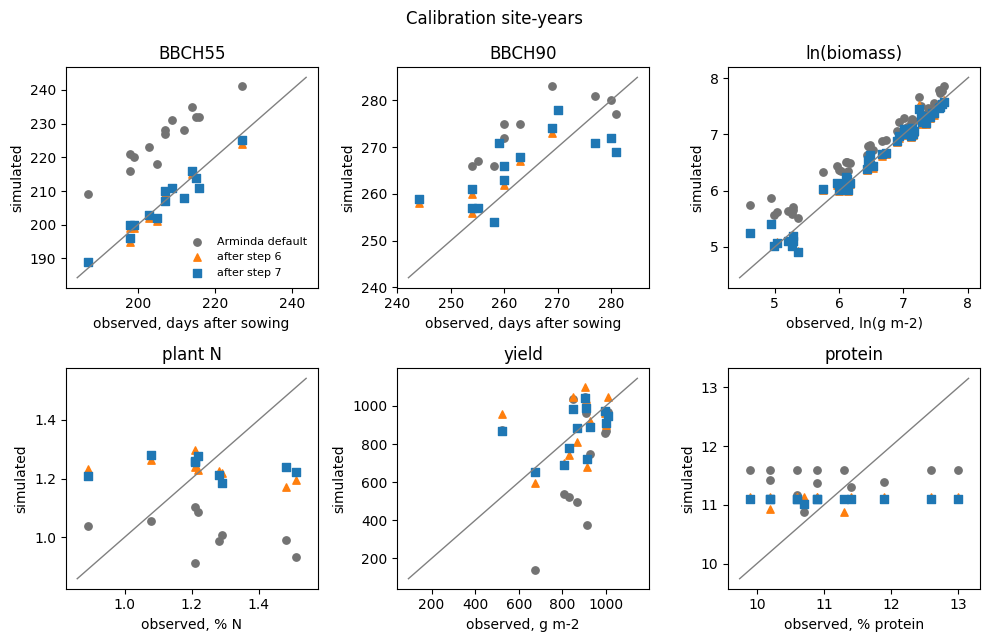

In [27]:
import matplotlib.pyplot as plt

STAGE = {"BBCH55": 1.0, "BBCH90": 2.0}
OBSERVED_STAGE = {
    environment["number"]: {"BBCH55": environment["heading"], "BBCH90": environment["maturity"]}
    for environment in environments
}
VARIABLES = ["BBCH55", "BBCH90", "biomass", "ln(biomass)", "plant N", "yield", "protein"]
PLOT_VARIABLES = ["BBCH55", "BBCH90", "ln(biomass)", "plant N", "yield", "protein"]
UNITS = {
    "BBCH55": "days after sowing",
    "BBCH90": "days after sowing",
    "ln(biomass)": "ln(g m-2)",
    "plant N": "% N",
    "yield": "g m-2",
    "protein": "% protein",
}


def calibration_pairs(values):
    """Observed and simulated values on the calibration site-years."""
    frozen = {name: torch.tensor(float(values[name]), dtype=torch.float64) for name in values}
    rows = []
    missed = []
    with torch.no_grad():
        for season in seasons:
            print(f"  site-year {season['number']}", flush=True)
            output = simulate(season, frozen)
            number = season["number"]
            for name, threshold in STAGE.items():
                day = hard_day(output["DVS"], threshold)
                observed = OBSERVED_STAGE[number][name]
                if day is None:
                    missed.append((number, name))
                    continue
                rows.append({"variable": name, "observed": observed, "simulated": day, "number": number})
            for day, observed_kg in season["biomass"]:
                if day < 0 or day >= output["TAGP"].shape[0]:
                    continue
                observed = observed_kg / 10.0
                simulated = float(output["TAGP"][day]) / 10.0
                rows.append({"variable": "biomass", "observed": observed, "simulated": simulated, "number": number})
                rows.append({
                    "variable": "ln(biomass)",
                    "observed": math.log(observed),
                    "simulated": math.log(max(simulated, 0.1)),
                    "number": number,
                })
            if season["yield_gm2"] is not None:
                rows.append({
                    "variable": "yield",
                    "observed": season["yield_gm2"],
                    "simulated": float(output["TWSO"][-1]) / 10.0,
                    "number": number,
                })
            if season["nitrogen"] is not None:
                crop_n = float(output["NamountLV"][-1] + output["NamountST"][-1] + output["NamountSO"][-1])
                predicted = 100.0 * crop_n / max(float(output["TAGP"][-1]), 1.0)
                rows.append({"variable": "plant N", "observed": season["nitrogen"], "simulated": predicted, "number": number})
            if season["protein"] is not None:
                predicted = 100.0 * PROTEIN_FACTOR * float(output["NamountSO"][-1]) / max(float(output["TWSO"][-1]), 1.0)
                rows.append({"variable": "protein", "observed": season["protein"], "simulated": predicted, "number": number})
    if missed:
        print("Stage not reached: " + ", ".join(f"{number} {name}" for number, name in missed))
    return pd.DataFrame(rows)


def agreement_rows(pairs, label):
    rows = []
    for variable in VARIABLES:
        block = pairs.loc[pairs["variable"] == variable]
        if block.empty:
            rows.append({"Variable": variable, "Parameters": label, "n": 0, "bias": None, "RMSE": None, "RRMSE": None})
            continue
        error = block["simulated"] - block["observed"]
        rmse = float((error.pow(2).mean()) ** 0.5)
        scale = float(block["observed"].abs().mean())
        rows.append({
            "Variable": variable,
            "Parameters": label,
            "n": int(len(block)),
            "bias": float(error.mean()),
            "RMSE": rmse,
            "RRMSE": rmse / scale,
        })
    return rows


parameter_sets = (
    ("Arminda default", arminda_values),
    ("after step 6", after_step6),
    ("after step 7", current),
)
PAIRS_NAME = "agmip_calibration_pairs.json"
PAIRS_URL = (
    "https://raw.githubusercontent.com/WUR-AI/diffWOFOST/"
    "agmip-calibration-protocol/docs/notebooks/agmip_calibration_pairs.json"
)


def _same_parameters(stored, values):
    if set(stored) != set(values):
        return False
    return all(abs(float(stored[name]) - float(values[name])) <= 1.0e-8 for name in values)


def _load_calibration_points(payload):
    points = {}
    for label, values in parameter_sets:
        stored = payload["sets"].get(label)
        if stored is None or not _same_parameters(stored["parameters"], values):
            return None
        points[label] = pd.DataFrame(stored["rows"])
    return points


def save_calibration_pairs(points):
    payload = {
        "note": (
            "Observed and simulated values on the calibration site-years for the Arminda "
            "default, the step 6 vector, and the Adam step 7 vector."
        ),
        "sets": {
            label: {
                "parameters": {name: float(values[name]) for name in values},
                "rows": points[label].to_dict(orient="records"),
            }
            for label, values in parameter_sets
        },
    }
    path = results_file().with_name(PAIRS_NAME)
    path.write_text(json.dumps(payload) + "\n")
    print(f"Stored calibration pairs in {path.name}.")


stored_pairs = load_stored(PAIRS_NAME, PAIRS_URL)
calibration_points = _load_calibration_points(stored_pairs)
if calibration_points is None and DO_NOT_RERUN:
    print("Using the stored calibration pairs without resimulating.")
    calibration_points = {
        label: pd.DataFrame(stored_pairs["sets"][label]["rows"])
        for label, _values in parameter_sets
    }
elif calibration_points is None:
    calibration_points = {}
    for label, values in parameter_sets:
        print(f"Calibration agreement, {label}.")
        calibration_points[label] = calibration_pairs(values)
    save_calibration_pairs(calibration_points)
else:
    print(f"Loaded calibration pairs from {PAIRS_NAME}.")
rows = []
for label, _values in parameter_sets:
    rows.extend(agreement_rows(calibration_points[label], label))
agreement = pd.DataFrame(rows)
display(agreement.round(3))

fig, axes = plt.subplots(2, 3, figsize=(10, 6.5))
styles = (
    ("Arminda default", "o", "0.45"),
    ("after step 6", "^", "C1"),
    ("after step 7", "s", "C0"),
)
for ax, variable in zip(axes.ravel(), PLOT_VARIABLES):
    limits = []
    for label, marker, color in styles:
        block = calibration_points[label]
        block = block.loc[block["variable"] == variable]
        if block.empty:
            continue
        ax.scatter(
            block["observed"], block["simulated"],
            marker=marker, s=28, color=color, label=label,
        )
        limits.extend(block["observed"].tolist())
        limits.extend(block["simulated"].tolist())
    if not limits:
        ax.set_title(variable)
        continue
    low, high = min(limits), max(limits)
    pad = 0.05 * (high - low or 1.0)
    ax.plot([low - pad, high + pad], [low - pad, high + pad], color="0.5", linewidth=1)
    ax.set_title(variable)
    ax.set_xlabel(f"observed, {UNITS[variable]}")
    ax.set_ylabel("simulated")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle("Calibration site-years")
fig.tight_layout()
plt.show()


## In-season biomass, crop nitrogen and soil mineral nitrogen

Above-ground biomass was measured repeatedly between March and harvest in 10 of the 14 calibration environments; plant nitrogen was measured only at harvest. Grey vertical lines mark mineral-fertilizer applications. The input file contains no manure applications, and these environments were not irrigated.

WOFOST's above-ground biomass (`TAGP`) includes living and dead leaves, stems, and grain. When a leaf class reaches the end of its lifespan, its biomass moves from the living-leaf pool to the dead-leaf pool; this transfer does not itself reduce total above-ground biomass. In this model configuration, nitrogen from senescing leaves is removed from the living-leaf pool at that day's concentration rather than retained in dead leaves or returned to the soil mineral-nitrogen pool. Nitrogen transferred to grain remains part of total above-ground nitrogen.

The soil curve shows ammonium plus nitrate across the soil profile. Fertilizer applications affect this pool, but the size and timing of the response depend on fertilizer composition, its representation in the soil layers, and subsequent soil processes; the change need not equal the applied nitrogen rate.

Loaded agmip_trajectories.json.
Loaded in-season curves from agmip_trajectories.json.


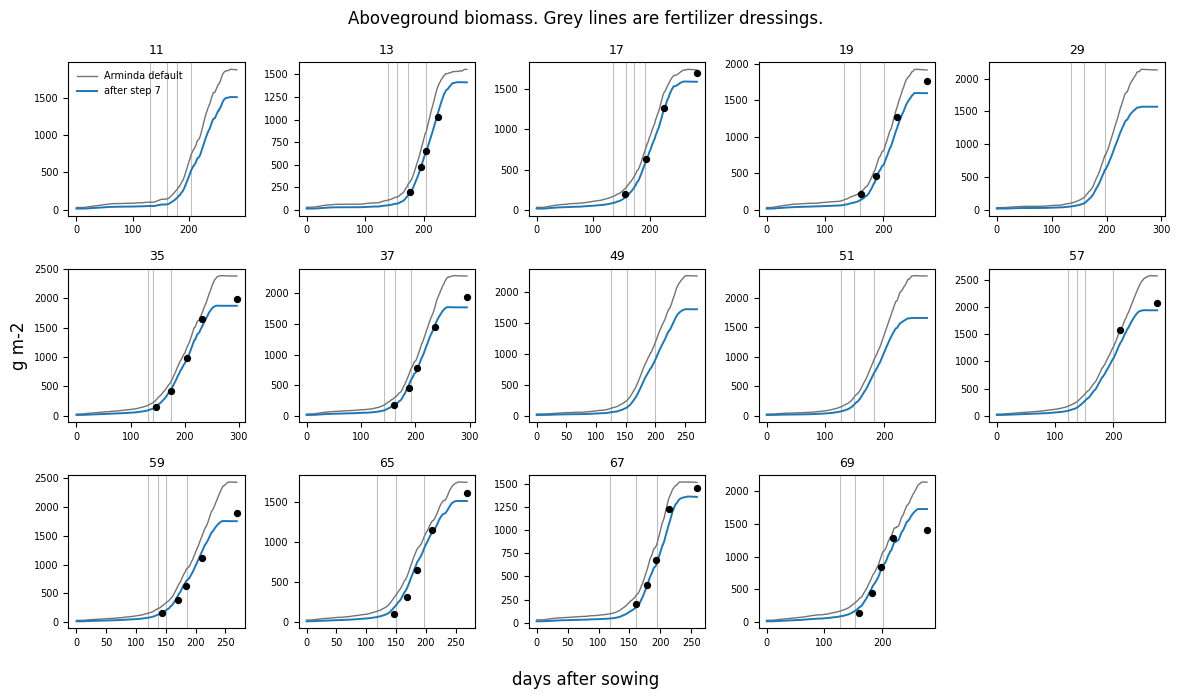

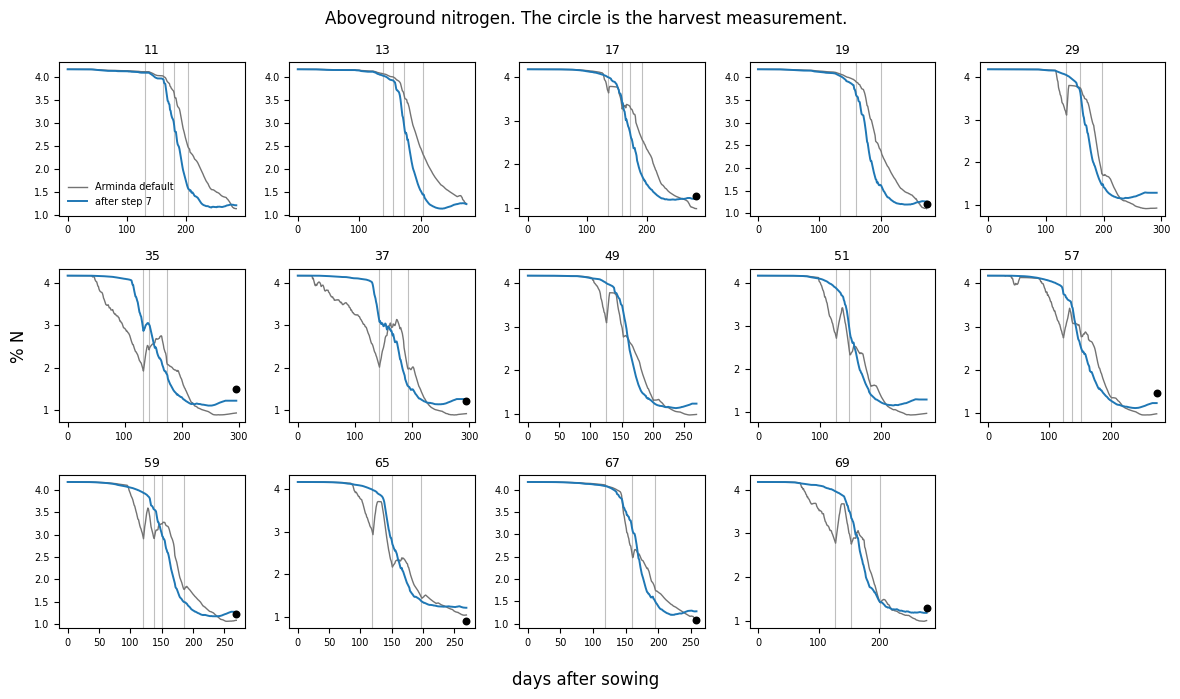

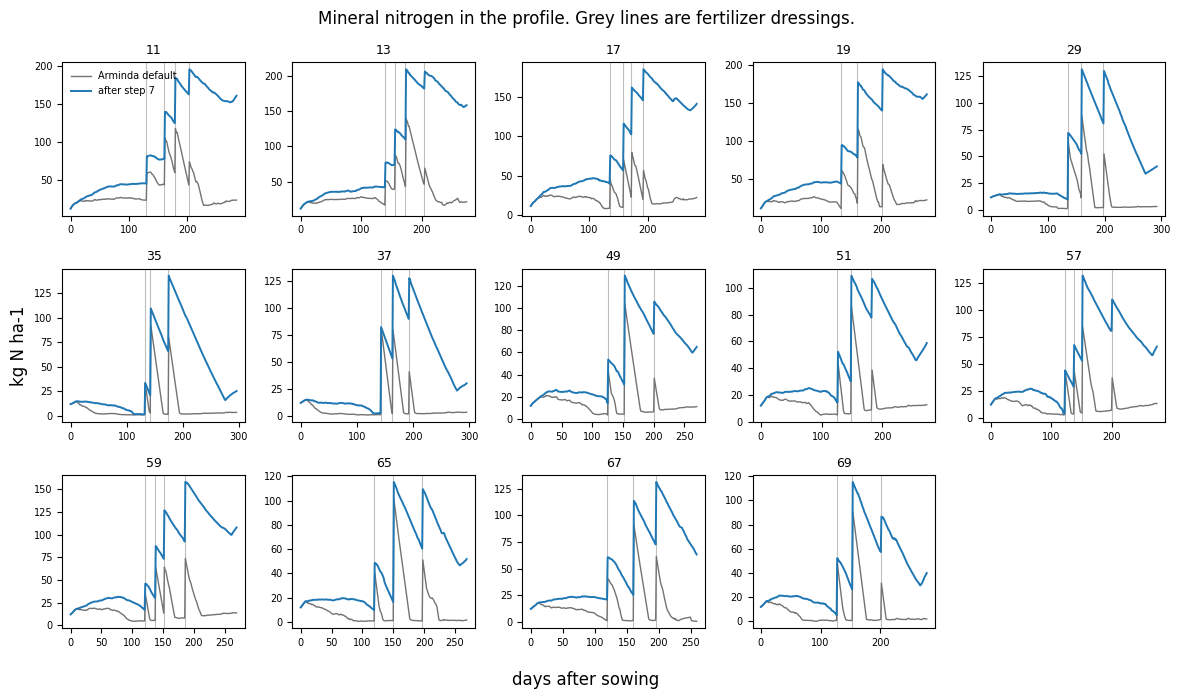

In [28]:
import matplotlib.pyplot as plt

for name in ("NH4T", "NO3T"):
    if name not in full_config.OUTPUT_VARS:
        full_config.OUTPUT_VARS.append(name)


def fertiliser_days(number, sowing):
    """Dressing dates as days after sowing, and the nitrogen rate in kg ha-1."""
    row = management.loc[management["Number"] == number].iloc[0]
    count = 0 if pd.isna(row.Number_of_fertilizer_doses) else int(row.Number_of_fertilizer_doses)
    days = []
    for index in range(1, count + 1):
        day = parse_date(getattr(row, f"Date_fertilization_{index}"))
        amount = cell_number(row, f"Amount_fertilization_{index}")
        if day is None or amount is None:
            continue
        days.append(((day - sowing).days, amount))
    return days


def observed_harvest_nitrogen(number, sowing):
    block = observations.loc[observations["Number"] == number].dropna(subset=["N_in_biomassHarvest"])
    if block.empty:
        return None
    return (parse_date(block.iloc[0]["Date"]) - sowing).days, float(block.iloc[0]["N_in_biomassHarvest"])


def trajectory(values):
    """Daily biomass, crop nitrogen percent and profile mineral nitrogen."""
    frozen = {name: torch.tensor(float(values[name]), dtype=torch.float64) for name in values}
    curves = {}
    with torch.no_grad():
        for season in seasons:
            print(f"  site-year {season['number']}", flush=True)
            output = simulate(season, frozen)
            sowing = season["rows"][0]["DAY"]
            tagp = output["TAGP"].detach()
            crop_n = output["NamountLV"] + output["NamountST"] + output["NamountSO"]
            curves[season["number"]] = {
                "biomass": tagp / 10.0,
                "nitrogen": 100.0 * crop_n.detach() / tagp.clamp(min=1.0),
                "soil_n": (output["NH4T"] + output["NO3T"]).detach(),
                "fertiliser": fertiliser_days(season["number"], sowing),
                "observed_biomass": [(day, kg / 10.0) for day, kg in season["biomass"]],
                "observed_nitrogen": observed_harvest_nitrogen(season["number"], sowing),
                "observed_soil": None,
            }
    return curves


TRAJECTORY_NAME = "agmip_trajectories.json"
TRAJECTORY_URL = (
    "https://raw.githubusercontent.com/WUR-AI/diffWOFOST/"
    "agmip-calibration-protocol/docs/notebooks/agmip_trajectories.json"
)


def _same_parameters(stored, values):
    if set(stored) != set(values):
        return False
    return all(abs(float(stored[name]) - float(values[name])) <= 1.0e-8 for name in values)


def _pack_series(curves):
    packed = {}
    for number, curve in curves.items():
        packed[str(number)] = {
            name: [float(value) for value in curve[name]]
            for name in ("biomass", "nitrogen", "soil_n")
        }
    return packed


def _curves_from_series(series):
    """Stored daily output, with observations and dressings taken from the files."""
    curves = {}
    for season in seasons:
        number = season["number"]
        stored = series[str(number)]
        sowing = season["rows"][0]["DAY"]
        curves[number] = {
            "biomass": torch.tensor(stored["biomass"], dtype=torch.float64),
            "nitrogen": torch.tensor(stored["nitrogen"], dtype=torch.float64),
            "soil_n": torch.tensor(stored["soil_n"], dtype=torch.float64),
            "fertiliser": fertiliser_days(number, sowing),
            "observed_biomass": [(day, kg / 10.0) for day, kg in season["biomass"]],
            "observed_nitrogen": observed_harvest_nitrogen(number, sowing),
            "observed_soil": None,
        }
    return curves


def save_trajectories(arminda_series, final_series):
    payload = {
        "note": (
            "Daily curves on the calibration site-years for the Arminda default and the "
            "Adam step 7 vector. Biomass is g m-2, crop nitrogen is a percentage, and "
            "soil mineral nitrogen is kg N ha-1."
        ),
        "arminda": {name: float(arminda_values[name]) for name in arminda_values},
        "after_step7": {name: float(current[name]) for name in current},
        "arminda_series": _pack_series(arminda_series),
        "after_step7_series": _pack_series(final_series),
    }
    path = results_file().with_name(TRAJECTORY_NAME)
    path.write_text(json.dumps(payload) + "\n")
    print(f"Stored in-season curves in {path.name}.")


stored_trajectories = load_stored(TRAJECTORY_NAME, TRAJECTORY_URL)
parameters_match = (
    _same_parameters(stored_trajectories["arminda"], arminda_values)
    and _same_parameters(stored_trajectories["after_step7"], current)
)
if parameters_match or DO_NOT_RERUN:
    if not parameters_match:
        print("Using the stored in-season curves without resimulating.")
    else:
        print(f"Loaded in-season curves from {TRAJECTORY_NAME}.")
    arminda_curves = _curves_from_series(stored_trajectories["arminda_series"])
    final_curves = _curves_from_series(stored_trajectories["after_step7_series"])
else:
    print("In-season curves, Arminda default.")
    arminda_curves = trajectory(arminda_values)
    print("In-season curves, after step 7.")
    final_curves = trajectory(current)
    save_trajectories(arminda_curves, final_curves)
numbers = sorted(final_curves)


def draw_trajectories(key, observed_key, ylabel, title):
    fig, axes = plt.subplots(3, 5, figsize=(12, 7), sharex=False)
    for ax, number in zip(axes.ravel(), numbers):
        final = final_curves[number]
        arminda = arminda_curves[number]
        days = torch.arange(final["biomass"].shape[0])
        for day, _amount in final["fertiliser"]:
            ax.axvline(day, color="0.75", linewidth=0.8, zorder=0)
        ax.plot(days, arminda[key], color="0.45", linewidth=1, label="Arminda default")
        ax.plot(days, final[key], color="C0", linewidth=1.4, label="after step 7")
        observed = final[observed_key]
        if observed_key == "observed_biomass" and observed:
            ax.scatter(
                [day for day, _value in observed],
                [value for _day, value in observed],
                s=18, color="black", zorder=3, label="observed",
            )
        elif observed_key != "observed_biomass" and observed is not None:
            ax.scatter([observed[0]], [observed[1]], s=22, color="black", zorder=3, label="observed")
        ax.set_title(str(number), fontsize=9)
        ax.tick_params(labelsize=7)
    for ax in axes.ravel()[len(numbers):]:
        ax.axis("off")
    axes[0, 0].legend(frameon=False, fontsize=7)
    fig.suptitle(title)
    fig.supxlabel("days after sowing")
    fig.supylabel(ylabel)
    fig.tight_layout()
    plt.show()


draw_trajectories(
    "biomass", "observed_biomass", "g m-2",
    "Aboveground biomass. Grey lines are fertilizer dressings.",
)
draw_trajectories(
    "nitrogen", "observed_nitrogen", "% N",
    "Aboveground nitrogen. The circle is the harvest measurement.",
)
draw_trajectories(
    "soil_n", "observed_soil", "kg N ha-1",
    "Mineral nitrogen in the profile. Grey lines are fertilizer dressings.",
)


## Comparing the calibration optimizers

Adam and Nelder–Mead are compared on three questions: whether they select similar parameters, whether their parameter estimates agree, and whether repeated starts satisfy the optimizer's stopping criterion. The tables summarize the saved results. SS and AICc are calculated separately for each variable group, with biomass fitted on the logarithmic scale.

Table A is Step 6. Each sum of squares uses that group's own objective, so a phenology value near 839 is not on the same scale as a biomass value near 1.3, and neither is the Step 7 score. Step 7 refits the selected parameters jointly. Its score divides each group's sum of squares by the variance from Adam's step 6 and adds the five terms.

Agreement on parameter selection does not imply agreement on parameter values or predictions.

The phenology diagnostics show the final objective values and parameter values from the 20 Nelder–Mead starts. Meeting the stopping criterion is distinct from finding a low objective value; a good fit alone does not establish convergence or parameter identifiability.


Loaded agmip_calibration_results.json.
Loaded agmip_nelder_mead_results.json.


### A. Parameter selection

,Variable group,Adam selected parameters,Adam SS,Nelder–Mead selected parameters,Nelder–Mead SS
0,Phenology,"TSUM1, TSUM2",839,"TSUM1, TSUM2",838
1,Biomass,"AMAX_REF, SPAN, TDWI",1.34,"AMAX_REF, SPAN, TDWI",1.27
2,Plant nitrogen,RNUPTAKEMAX,0.398,RNUPTAKEMAX,0.279
3,Yield,REALLOC_STEM_FRACTION,3.56e+05,REALLOC_STEM_FRACTION,2.03e+05
4,Grain protein,NMAXSO,10.3,NMAXSO,10.4


**Search status.** The saved Nelder–Mead Step 6 search completed. The Adam search was interrupted during the grain-protein candidate tests: `NRESIDST` was cut off at step 37 and `TCNT` was not started. Therefore, those Adam candidate decisions are incomplete.

### B. Parameter estimates

,Parameter,Arminda default,Adam Step 6,Adam Step 7,Nelder–Mead Step 6
0,TSUM1,886.00,618.428,629.387,618.447
1,TSUM2,860.00,956.094,957.408,961.402
2,AMAX_REF,40.20,29.907,31.992,31.982
3,SPAN,35.00,51.785,35.742,34.101
4,TDWI,593.00,325.131,286.425,283.721
5,RNUPTAKEMAX,4.26,1.294,1.568,1.309
6,REALLOC_STEM_FRACTION,0.20,0.131,0.203,0.327
7,NMAXSO,0.02,0.020,0.019,0.019


No results file at /content/agmip_step7_scores.json. Downloading the stored search.
Loaded agmip_step7_scores.json.


### Step 7. Joint weighted score

This is not the sum of squares in table A. Each group's sum of squares is divided by the variance from Adam's step 6, and the five terms are added. A lower score is a better joint fit. Nelder–Mead includes only the starts that have finished.

,Search,Starts finished,Best weighted SS,Median weighted SS
0,Adam,20 / 20,93.12,112.18
1,Nelder–Mead,15 / 20,111.81,313.81


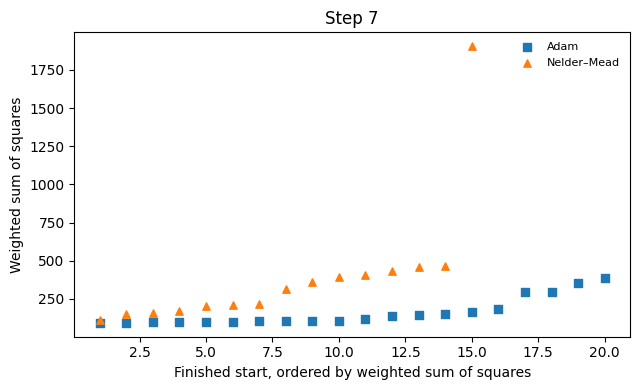

### C. Phenology: sensitivity to initialization

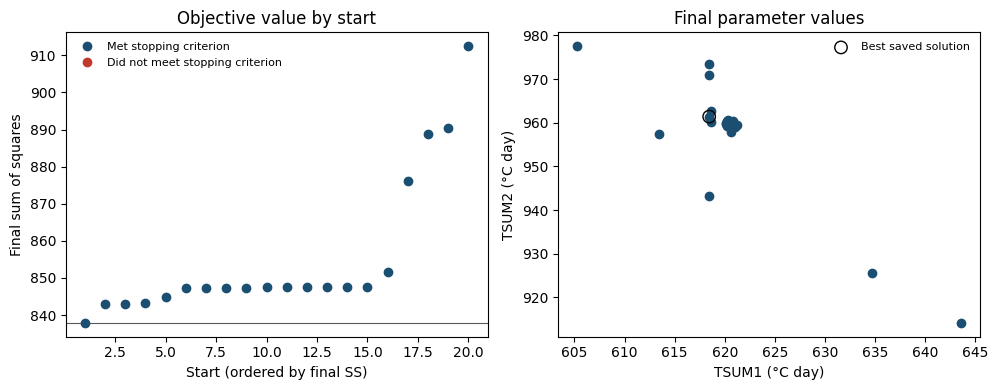

All 20 phenology starts met the stopping criterion. The finished sums of squares still differ, so meeting that criterion does not mean every start found the same solution.

### D. Candidate-selection details

,Group,Parameters tested,Adam SS,Adam AICc,Adam ΔAICc,Adam,Nelder–Mead SS,Nelder–Mead AICc,Nelder–Mead ΔAICc,Nelder–Mead
0,Biomass,"AMAX_REF, SPAN",1.64,-140.49,—,Major,1.64,-140.52,—,Major
1,Biomass,"AMAX_REF, SPAN, TDWI",1.34,-146.92,-6.43,Retained,1.27,-149.24,-8.72,Retained
2,Biomass,"AMAX_REF, SPAN, TDWI, RGRLAI",1.34,-144.59,+2.34,Rejected,1.27,-146.81,+2.43,Rejected
3,Grain protein,NMAXSO,10.3,-0.71,—,Major,10.4,-0.51,—,Major
4,Grain protein,"NMAXSO, NRESIDLV",9.84,1.58,+2.30,Rejected,9.73,1.43,+1.94,Rejected
5,Grain protein,"NMAXSO, NRESIDST",—,—,—,Incomplete,10.1,1.94,+2.45,Rejected
6,Grain protein,"NMAXSO, TCNT",—,—,—,Not started,9.96,1.74,+2.25,Rejected
7,Phenology,"TSUM1, TSUM2",839,99.68,—,Major,838,99.64,—,Major
8,Phenology,"TSUM1, TSUM2, DLO",839,102.20,+2.52,Rejected,838,102.16,+2.52,Rejected
9,Phenology,"TSUM1, TSUM2, VERNBASE",839,102.20,+2.52,Rejected,838,102.16,+2.52,Rejected


In [29]:
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

adam = load_results()
nelder = load_nelder()
phenology = nelder["phenology"]
majors = phenology["rounds"][0]


def phenology_rows():
    """Phenology is stored with the starts, not in the group table."""
    rows = []
    adam_major = False
    nelder_major = False
    for adam_round, nelder_round in zip(phenology["adam_history"], phenology["rounds"]):
        if adam_round["parameters"] != nelder_round["names"]:
            raise ValueError("Adam and Nelder-Mead tested different phenology parameters")
        if adam_round["kept"]:
            adam_kept = "yes" if adam_major else "major"
            adam_major = True
        else:
            adam_kept = "no"
        if nelder_round["kept"]:
            nelder_kept = "yes" if nelder_major else "major"
            nelder_major = True
        else:
            nelder_kept = "no"
        rows.append({
            "Group": "phenology",
            "Parameters": ", ".join(adam_round["parameters"]),
            "Adam SS": adam_round["ss"],
            "Adam AICc": adam_round["aicc"],
            "Adam kept": adam_kept,
            "Nelder-Mead SS": nelder_round["best_ss"],
            "Nelder-Mead AICc": nelder_round["aicc"],
            "Nelder-Mead kept": nelder_kept,
        })
    return rows


stored_groups = pd.concat(
    [pd.DataFrame(phenology_rows()), pd.DataFrame(nelder["groups"])],
    ignore_index=True,
)

# ---------------------------------------------------------------------
# A. Main result: parameter selection and search status
# ---------------------------------------------------------------------

group_names = {
    "plant_biomass": "Biomass",
    "plant_N_content": "Plant nitrogen",
    "yield": "Yield",
    "seed_protein": "Grain protein",
    "phenology": "Phenology",
}

def normalize_decision(value):
    """Normalize the saved decision labels for reporting."""
    value = str(value).strip().lower()
    if value in {"major", "yes", "retained"}:
        return "Retained"
    if value in {"no", "rejected"}:
        return "Rejected"
    if "cut off" in value or "cutoff" in value:
        return "Incomplete"
    if "not started" in value:
        return "Not started"
    return str(value)

def selected_model(frame, decision_col, ss_col):
    """Last retained parameter set in each group, and its sum of squares."""
    chosen = {}
    scores = {}
    for group, part in frame.groupby("Group", sort=False):
        retained = part[part[decision_col].map(normalize_decision) == "Retained"]
        if retained.empty:
            chosen[group] = "No completed selection"
            scores[group] = "—"
            continue
        row = retained.iloc[-1]
        chosen[group] = str(row["Parameters"])
        score = row[ss_col]
        scores[group] = "—" if pd.isna(score) else f"{float(score):.3g}"
    return chosen, scores

adam_selected, adam_ss = selected_model(stored_groups, "Adam kept", "Adam SS")
nm_selected, nm_ss = selected_model(stored_groups, "Nelder-Mead kept", "Nelder-Mead SS")

summary_rows = []
for group in stored_groups["Group"].drop_duplicates():
    summary_rows.append({
        "Variable group": group_names.get(group, group),
        "Adam selected parameters": adam_selected.get(group, "—"),
        "Adam SS": adam_ss.get(group, "—"),
        "Nelder–Mead selected parameters": nm_selected.get(group, "—"),
        "Nelder–Mead SS": nm_ss.get(group, "—"),
    })

selection_summary = pd.DataFrame(summary_rows)

display(Markdown("### A. Parameter selection"))
display(selection_summary)

display(Markdown(
    "**Search status.** The saved Nelder–Mead Step 6 search completed. "
    "The Adam search was interrupted during the grain-protein candidate "
    "tests: `NRESIDST` was cut off at step 37 and `TCNT` was not started. "
    "Therefore, those Adam candidate decisions are incomplete."
))

# ---------------------------------------------------------------------
# B. Parameter estimates
# ---------------------------------------------------------------------

display(Markdown("### B. Parameter estimates"))

names = [
    "TSUM1", "TSUM2", "AMAX_REF", "SPAN", "TDWI",
    "RNUPTAKEMAX", "REALLOC_STEM_FRACTION", "NMAXSO",
]

estimates = pd.DataFrame({
    "Parameter": names,
    "Arminda default": [nelder["arminda"][name] for name in names],
    "Adam Step 6": [adam["after_step6"][name] for name in names],
    "Adam Step 7": [adam["after_step7"][name] for name in names],
    "Nelder–Mead Step 6": [
        nelder["after_step6"][name] for name in names
    ],
})

display(estimates.round(3))

STEP7_NAME = "agmip_step7_scores.json"
STEP7_URL = (
    "https://raw.githubusercontent.com/WUR-AI/diffWOFOST/"
    "agmip-calibration-protocol/docs/notebooks/agmip_step7_scores.json"
)
step7 = load_stored(STEP7_NAME, STEP7_URL)

def step7_row(label, block):
    scores = sorted(float(run["ss"]) for run in block["runs"])
    middle = len(scores) // 2
    if len(scores) % 2:
        midpoint = scores[middle]
    else:
        midpoint = 0.5 * (scores[middle - 1] + scores[middle])
    return {
        "Search": label,
        "Starts finished": f"{len(scores)} / {block['n_planned']}",
        "Best weighted SS": scores[0],
        "Median weighted SS": midpoint,
    }

step7_table = pd.DataFrame([
    step7_row("Adam", step7["adam"]),
    step7_row("Nelder–Mead", step7["nelder_mead"]),
])
display(Markdown(
    "### Step 7. Joint weighted score\n\n"
    "This is not the sum of squares in table A. "
    "Each group's sum of squares is divided by the variance from Adam's step 6, "
    "and the five terms are added. A lower score is a better joint fit. "
    "Nelder–Mead includes only the starts that have finished."
))
display(step7_table.round(2))

fig, ax = plt.subplots(figsize=(6.5, 4))
for label, key, color, marker in (
    ("Adam", "adam", "C0", "s"),
    ("Nelder–Mead", "nelder_mead", "C1", "^"),
):
    scores = sorted(float(run["ss"]) for run in step7[key]["runs"])
    ax.scatter(range(1, len(scores) + 1), scores, marker=marker, color=color, s=28, label=label)
ax.set_xlabel("Finished start, ordered by weighted sum of squares")
ax.set_ylabel("Weighted sum of squares")
ax.set_title("Step 7")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

# ---------------------------------------------------------------------
# C. Phenology optimization diagnostics
# ---------------------------------------------------------------------

display(Markdown("### C. Phenology: sensitivity to initialization"))

runs = majors["runs"]
order = np.argsort([run["ss"] for run in runs])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for position, run_index in enumerate(order):
    run = runs[int(run_index)]
    color = "#1b4f72" if run["met_stopping_test"] else "#c0392b"
    axes[0].scatter(position + 1, run["ss"], color=color, zorder=3)

axes[0].axhline(majors["best_ss"], color="0.35", lw=0.8)
axes[0].set_xlabel("Start (ordered by final SS)")
axes[0].set_ylabel("Final sum of squares")
axes[0].set_title("Objective value by start")

for run in runs:
    color = "#1b4f72" if run["met_stopping_test"] else "#c0392b"
    axes[1].scatter(
        run["final"]["TSUM1"],
        run["final"]["TSUM2"],
        color=color,
        zorder=3,
    )

axes[1].scatter(
    [majors["best_final"]["TSUM1"]],
    [majors["best_final"]["TSUM2"]],
    facecolors="none",
    edgecolors="black",
    s=80,
    zorder=4,
    label="Best saved solution",
)
axes[1].set_xlabel("TSUM1 (°C day)")
axes[1].set_ylabel("TSUM2 (°C day)")
axes[1].set_title("Final parameter values")

met = plt.Line2D(
    [0], [0], marker="o", color="#1b4f72", ls="",
    label="Met stopping criterion",
)
not_met = plt.Line2D(
    [0], [0], marker="o", color="#c0392b", ls="",
    label="Did not meet stopping criterion",
)
axes[0].legend(
    handles=[met, not_met], fontsize=8, frameon=False
)
axes[1].legend(fontsize=8, frameon=False)

fig.tight_layout()
plt.show()

n_starts = len(runs)
n_met = sum(run["met_stopping_test"] for run in runs)
if n_met == n_starts:
    stopping_text = (
        f"All {n_starts} phenology starts met the stopping criterion. "
        "The finished sums of squares still differ, so meeting that criterion "
        "does not mean every start found the same solution."
    )
else:
    stopping_text = (
        f"Of the {n_starts} phenology starts, **{n_met} met the stopping "
        f"criterion**. The remaining {n_starts - n_met} stopped at the "
        "evaluation limit. The best objective value is not, by itself, "
        "evidence that the optimizer converged successfully."
    )
display(Markdown(stopping_text))

# ---------------------------------------------------------------------
# D. Detailed candidate-by-candidate decisions
# ---------------------------------------------------------------------

display(Markdown("### D. Candidate-selection details"))

def selection_view(frame, ss_col, aicc_col, kept_col, prefix):
    groups = frame[
        ["Group", "Parameters", ss_col, aicc_col, kept_col]
    ].copy()
    groups.columns = ["Group", "Parameters", "SS", "AICc", "Kept"]
    groups["Group"] = (
        groups["Group"].map(group_names).fillna(groups["Group"])
    )
    groups["ΔAICc"] = np.nan
    groups["Decision"] = ""

    for _, indices in groups.groupby("Group", sort=False).groups.items():
        best_aicc = None
        for i in indices:
            decision = normalize_decision(groups.loc[i, "Kept"])
            aicc_value = groups.loc[i, "AICc"]

            if pd.isna(aicc_value):
                groups.loc[i, "Decision"] = decision
                continue

            aicc_value = float(aicc_value)

            if decision == "Retained":
                groups.loc[i, "Decision"] = (
                    "Major" if best_aicc is None else "Retained"
                )
                if best_aicc is not None:
                    groups.loc[i, "ΔAICc"] = aicc_value - best_aicc
                best_aicc = aicc_value
            elif decision == "Rejected":
                groups.loc[i, "Decision"] = "Rejected"
                if best_aicc is not None:
                    groups.loc[i, "ΔAICc"] = aicc_value - best_aicc
            else:
                groups.loc[i, "Decision"] = decision

    groups = groups.rename(columns={"Parameters": "Parameters tested"})
    groups["SS"] = groups["SS"].map(
        lambda x: "—" if pd.isna(x) else f"{x:.3g}"
    )
    groups["AICc"] = groups["AICc"].map(
        lambda x: "—" if pd.isna(x) else f"{x:.2f}"
    )
    groups["ΔAICc"] = groups["ΔAICc"].map(
        lambda x: "—" if pd.isna(x) else f"{x:+.2f}"
    )
    groups = groups.rename(columns={
        "SS": f"{prefix} SS",
        "AICc": f"{prefix} AICc",
        "ΔAICc": f"{prefix} ΔAICc",
        "Decision": prefix,
    })
    return groups[[
        "Group", "Parameters tested",
        f"{prefix} SS", f"{prefix} AICc",
        f"{prefix} ΔAICc", prefix,
    ]]

candidate_selection = selection_view(
    stored_groups, "Adam SS", "Adam AICc", "Adam kept", "Adam"
).merge(
    selection_view(
        stored_groups,
        "Nelder-Mead SS",
        "Nelder-Mead AICc",
        "Nelder-Mead kept",
        "Nelder–Mead",
    ),
    on=["Group", "Parameters tested"],
    how="outer",
)

display(candidate_selection.reset_index(drop=True))
